# Median-background subtraction: reference study and paired evaluation

**Main case: Fireball IV HRM6. The same notebook also runs on BTV or HRM3, one camera/configuration at a time.**

Choose the beam-analysis interval, background-window lengths and numbers of backgrounds in the settings cell.
The notebook constructs each available pixel-wise median, subtracts it from **the same beam shots**, and compares
several explicit measures. It also evaluates **no correction** and a **scalar pedestal correction**.

This notebook continues the thesis distinction: background includes offsets, spatial structure and fluctuations;
recurrent structure is not itself evidence of radiation damage. The primary question here is whether a reference
reduces unwanted background and improves beam/background separation under the selected conditions.

The method definitions are fixed before inspecting the results. Improvements, ties, deteriorations and undefined
ratios are all retained. There is no requirement that every metric improve: removal of a pedestal can be useful
even when a fluctuation-based metric remains unchanged.

**No corrected-image parquet is written.** Signed corrected images are calculated for measurements and figures.
Optional outputs are CSV tables, settings, reference membership, median-reference `.npy` files and PNG/PDF figures.
Original parquet files are read only.

**Data availability:** this notebook was developed from your four supplied notebooks. Their CERN `/eos/...`
datasets must be accessible in SWAN to obtain experimental results; the supplied notebooks do not include those data.

**ROI update:** HRM6 now uses separate halo/compact ellipse proposals and a fixed screen exclusion.
The halo ellipse has an editable centre offset relative to the bright spot. Screen-only pixels are excluded
from beam-ROI and outside-region statistics; the signal mask is the ellipse intersected with the screen outline.
No-beam validation remains full-image and the background construction/selection procedure is unchanged.
Old outputs have been cleared: run this version to obtain metrics for the new masks.


## How to run this notebook

1. Edit **Settings**: camera/path, filter, analysis start/end, image orientation and any known camera settings.
2. Run through **ROI preview**. Review the screen outline, halo and compact ellipses, and the separate off-screen background region.
   The saved axes are used for plots; confirm their unit. If necessary, adjust the ROI and rerun from the settings.
3. Run the reference construction, validation and beam evaluation cells.
4. Read the background-validation tables first, then the paired beam summary, grid plots and individual images.
5. Repeat with BTV or HRM3 by changing the same settings cell. Keep the metric definitions unchanged.

For your original HRM6 example, the defaults use **12 June 2026, 15:25–24:00 Geneva time**. To study all of 9 June,
use `ANALYSIS_START_LOCAL = "2026-06-09 00:00:00"` and `ANALYSIS_END_LOCAL = "2026-06-10 00:00:00"`.
Two reference timings are compared: windows ending at the analysis start (`prior`) and windows ending at the
analysis end (`offline`). For the 9 June example, a 24-hour prior window uses 8 June and a 24-hour offline window
uses 9 June, with reserved validation frames excluded. Offline references can use acquisitions later than a beam
shot and therefore describe retrospective correction. Insufficient configurations are **skipped with their actual
counts**, rather than silently using fewer images.

One fixed reference per candidate is applied to the entire analysis interval. This is a batch reference study,
not a moving per-shot reference. Shorten the interval if one reference cannot represent a rapidly changing day.

For HRM6, review shot 63 (screen reference) and shot 77 (the shifted-halo example) in the ROI previews.
`HALO_CENTER_OFFSET_XY_PIXELS = (0, 40)` initially moves the halo aperture 40 image rows down from the
bright-spot centre. It is a visual starting correction, not a fitted halo displacement. Compact apertures retain
zero offset. Adjust it from raw-image geometry, not from whichever value increases a subtraction metric.
If you change the interval, choose a screen-visible `SCREEN_REFERENCE_SHOT` in that interval.


In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import ast
import gc
import json
import re
import shutil
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyarrow as pa
import pyarrow.dataset as ds
from scipy.ndimage import median_filter, uniform_filter, label as connected_label, binary_fill_holes, binary_dilation
from matplotlib.patches import Rectangle
from matplotlib.path import Path as PolygonPath
from matplotlib.colors import ListedColormap
from IPython.display import display

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "savefig.dpi": 180, "pdf.fonttype": 42,
})
RAW_COLOUR, CORRECTED_COLOUR, SCALAR_COLOUR = "#0072B2", "#D55E00", "#009E73"

## 1. Settings — edit this cell

The acquisition timezone remains **Europe/Zurich**, even when you run the notebook from Greece.
The start is included and the end excluded. Both BCT values must be finite: missing BCTs are never treated as zero.

`None` for exposure/gain/screen means infer the **single logged configuration** in the target beam interval.
If more than one is present, an inventory is displayed and the notebook asks you to narrow these settings.
Missing metadata are labelled missing; matching missing values cannot establish physically matched acquisition settings.

The image dimension order defaults to `height_width`, matching the supplied HRM6 notebooks and their `(850, 700)`
arrays. Confirm this for every other dataset rather than inferring orientation from a camera name.

**ROI controls:** `auto` keeps the previous square for BTV/HRM3 and selects `ellipse_screen` for HRM6.
The halo and compact templates share the original automatic bright-spot centre finder, but can have separate
centre offsets. An absolute per-shot `center_xy` override bypasses the group offset.
Automatic compact/halo assignments and the proposed screen boundary need visual review; they do not establish
target state or physically separate overlapping halo/screen illumination.


In [2]:
# Camera and source parquet (backgrounds + beam images).
CAMERA_NAME = "HRM6"
PARQUET_PATH = Path(
    "/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/"
    "Fireball_IV/HRM6/HRM6_merged.parquet"
)
SELECTED_FILTER = "OD1"

# BTV alternative:
# CAMERA_NAME = "BTV_660524"
# PARQUET_PATH = Path("/eos/user/v/vtsoukni/SWAN_projects/MY HRMT64 image analysis/"
#                     "Fireball_IV/BTV/TT66.BTV.660524_merged.parquet")
# SELECTED_FILTER = "OD0"

ANALYSIS_START_LOCAL = "2026-06-12 15:25:00"
ANALYSIS_END_LOCAL   = "2026-06-13 00:00:00"
LOCAL_TIMEZONE = "Europe/Zurich"

SELECTED_EXPOSURE_US = None
SELECTED_GAIN = None
SELECTED_SCREEN = None
SELECTED_SHAPE = None                 # optional (height, width), e.g. (850, 700)
DIMENSION_ORDER = "height_width"      # or "width_height"

# Crossed study: vary N at fixed window; vary window at fixed N.
BACKGROUND_COUNTS = [10, 25, 50]
BACKGROUND_WINDOW_HOURS = [6, 24, 48]
REFERENCE_END_CHOICES = ["analysis_start", "analysis_end"]  # prior and retrospective/offline references
# Use ["analysis_start"] alone if references must be available before the analysis interval.
BACKGROUND_GAP_HOURS = 0              # 0: window ends at each chosen reference endpoint
# Gap is measured back from EACH chosen endpoint. For the prior endpoint:
# gap=24 and window=24 uses [start-48 h, start-24 h).
# Duration and age are different; rerun with another gap to study age at fixed duration.

# Deterministic sampling, spread through the time-sorted eligible backgrounds.
# Exact rule: round(linspace(0, pool_size-1, N)); equal index spacing, not equal clock spacing.
# No reference subset is selected by its resulting SNR.

N_VALIDATION_BACKGROUNDS = 20          # target-interval no-beam images, separate from all references
# When offline windows are enabled, reserve at most half of the target no-beam pool
# for validation, leaving the other half eligible for same-day reference construction.
MAX_BEAM_SHOTS = None                 # None = all; a test cap uses evenly spread shots

# Existing Chapter 4 image exclusions, applied ONLY to no-beam candidates/validation images.
# "auto": BTV -> Q99 - median > 4 ADU; HRM3 -> BOTH mean and median > 150 ADU; HRM6 -> neither.
BACKGROUND_QUALITY_RULE = "auto"     # or "none", "btv", "hrm3"

# Freeze raw-image masks before testing any subtraction.
ROI_MODE = "auto"                    # auto: HRM6 -> ellipse_screen; other cameras -> original square
ROI_SIZE_PIXELS = 250                 # used only in square mode
MANUAL_CENTER_XY = None               # optional bright-spot centre (x, y), in pixels
CENTER_MEDIAN_FILTER_SIZE = 3         # only a disposable geometry-finding copy is filtered
CENTER_SMOOTHING_SIZE = 9
CENTER_TOP_PERCENTILE = 99.6
OUTSIDE_MARGIN_PIXELS = 0             # original square-mode margin only

# Ellipse semi-axes are radii, in pixels. Initial values still require visual review.
HALO_SEMI_AXES_PIXELS = (150, 220)
HALO_ANGLE_DEG = 0.0
HALO_CENTER_OFFSET_XY_PIXELS = (0, 40) # +y = DOWN in image rows; independent of plotted y-axis units
COMPACT_SEMI_AXES_PIXELS = (35, 55)
COMPACT_ANGLE_DEG = 0.0
COMPACT_CENTER_OFFSET_XY_PIXELS = (0, 0)

# 1-based chronological shot numbers in the FULL interval, before any MAX_BEAM_SHOTS cap.
PROTON_ONLY_SHOTS = []                # confirmed from run log / visual review
HALO_SHOTS = []                       # optional confirmed halo-template shots
AUTO_PROPOSE_KIND = True              # unlabelled choices remain explicitly marked for review
BROAD_LIGHT_MIN_EXCESS_ADU = 10.0      # provisional image-appearance heuristic, not a target-state test
SHOT_ROI_OVERRIDES = {
    # 77: {"kind": "halo", "center_offset_xy": (0, 50)},
    # Or absolute final "center_xy": (x, y), "semi_axes": (rx, ry), "angle_deg": 0.
}

# Fixed screen outline from one screen-visible raw shot, or a manually supplied polygon.
SCREEN_REFERENCE_SHOT = 63            # select a new screen-visible shot when changing the interval
SCREEN_POLYGON_PIXELS = None          # optional ordered [(x0, y0), (x1, y1), ...], in image pixels
SCREEN_LEVEL_ABOVE_BORDER_ADU = 20.0  # initial outline proposal; review before using results
SCREEN_GUARD_PIXELS = 15
SIGNAL_GUARD_PIXELS = 10
ROI_EXTRA_PREVIEW_SHOTS = [63, 77]
SHOW_ALL_ROI_PREVIEWS = False          # True displays every measured beam shot


EXCESS_DELTA_ADU = 5.0               # same Chapter 4 median-relative tail descriptor
SATURATION_ADU = 4095                 # verify bit depth; None disables saturation flags
# SBR is omitted if the positive outside mean is <= this value. This is a validity
# rule, NOT a denominator floor. Near-zero signed residuals do not have a stable SBR.
SBR_MIN_BACKGROUND_ADU = 1.0

TIMESTAMP_COLUMN = "cycleStampGlob"
TIMESTAMP_UNIT = "ns"
NAIVE_TIMESTAMP_TIMEZONE = "UTC"      # if using a naive cyclestamp_dt, check its actual convention
IMAGE_COLUMN, DIMENSIONS_COLUMN = "image_elements", "image_dimensions"
FILTER_COLUMN = "filter"
BCT_COLUMNS = ["TT60.BCTFI.610225:TOTAL_INTENSITY", "TT66.BCTFI.660298:TOTAL_INTENSITY"]
BEAM_THRESHOLD = 5e8
EXPOSURE_COLUMN, GAIN_COLUMN, SCREEN_COLUMN = "camera_exposure_time_us", "camera_gain", "screen"
X_AXIS_COLUMN, Y_AXIS_COLUMN = "pos1_elements", "pos2_elements"
AXIS_UNIT = "mm"                      # confirm logged pos1/pos2 units; use "pixel" if appropriate
AXIS_SCALE = (1.0, 1.0)               # only change using a known calibration
CHECK_AXES_MATCH = True

BATCH_SIZE = 2                       # large image payloads: keep this small
MAX_STACK_GIB = 1.0                  # maximum estimated temporary reference-stack memory
CACHE_PARENT = None                  # None = local temporary storage; change if disk space is limited
QUICK_LOOK_SHOTS = 3
N_EXAMPLE_SHOTS = 3                  # evenly spread in time, not chosen for improvement
SHOW_REFERENCE = None                # None = validation-selected reference, or explicit config_id

SAVE_RESULTS = True
SAVE_MEDIAN_ARRAYS = True
OUTPUT_BASE_DIR = Path("median_subtraction_study_results")

## 2. Read the metadata and select one acquisition configuration

The scan preserves a global source-row identifier. No Arrow BCT filter is used, avoiding the filtering problem
encountered in the previous notebooks and keeping row identifiers consistent between passes.
Logged filter, shape, exposure, gain and screen must match between reference, validation and beam images.
Axis arrays are also checked when available. Rows with invalid images are recorded later.

No-beam means **TT60 = 0 AND TT66 = 0**. Beam means **TT60 > 5×10⁸ AND TT66 > 5×10⁸**.
Other rows, including rows with missing/nonfinite BCTs, are not silently reassigned to either category.

In [3]:
def local_time(value):
    t = pd.Timestamp(value)
    return t.tz_localize(LOCAL_TIMEZONE) if t.tzinfo is None else t.tz_convert(LOCAL_TIMEZONE)

def normalise_filter(value):
    if value is None or pd.isna(value):
        return "missing"
    s = re.sub(r"[^A-Z0-9.]", "", str(value).upper())
    m = re.fullmatch(r"(?:OD)?(\d+)(?:\.0+)?", s)
    return f"OD{int(m.group(1))}" if m else s

def metadata_text(value):
    if value is None or pd.isna(value):
        return "missing"
    try:
        return f"{float(value):.12g}"
    except (ValueError, TypeError):
        return str(value).strip()

def shape_from_dimensions(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    a = np.asarray(value)
    if a.ndim != 1 or a.size != 2 or not np.isfinite(a.astype(float)).all():
        raise ValueError("Invalid image dimensions")
    if not np.equal(a.astype(float), a.astype(int)).all():
        raise ValueError("Noninteger image dimensions")
    shape = tuple(int(x) for x in a)
    if min(shape) <= 0:
        raise ValueError("Nonpositive image dimension")
    return shape if DIMENSION_ORDER == "height_width" else shape[::-1]

def image_from_record(row):
    shape = shape_from_dimensions(row[DIMENSIONS_COLUMN])
    image = np.asarray(row[IMAGE_COLUMN], dtype=np.float32)
    if image.size != np.prod(shape) or image.ndim not in (1, 2):
        raise ValueError("Image length/dimensions mismatch")
    if image.ndim == 2 and image.shape != shape:
        raise ValueError("Stored 2D shape contradicts configured dimension order")
    image = image.reshape(shape)
    if not np.isfinite(image).all():
        raise ValueError("Nonfinite pixel value")
    return image

def safe_shape(value):
    try:
        return shape_from_dimensions(value)
    except (ValueError, TypeError, SyntaxError, OverflowError):
        return None

def timestamps_local(series):
    if pd.api.types.is_numeric_dtype(series):
        t = pd.to_datetime(series.where(series != 0), unit=TIMESTAMP_UNIT, utc=True, errors="coerce")
    else:
        # ISO strings and Arrow datetime columns; no numeric strings are guessed.
        t = pd.to_datetime(series, errors="coerce")
        if t.dt.tz is None:
            t = t.dt.tz_localize(NAIVE_TIMESTAMP_TIMEZONE, ambiguous="NaT", nonexistent="NaT")
    return t.dt.tz_convert(LOCAL_TIMEZONE)

def spread_sample(frame, n):
    frame = frame.sort_values(["timestamp", "row_id"])
    if n < 1 or len(frame) < n:
        raise ValueError("Exact requested sample count is not available")
    positions = np.rint(np.linspace(0, len(frame)-1, n)).astype(int)
    if len(np.unique(positions)) != n:
        raise RuntimeError("Sample indices unexpectedly repeat")
    return frame.iloc[positions].copy()

def iter_image_rows(row_ids):
    wanted = set(int(x) for x in row_ids)
    columns = [IMAGE_COLUMN, DIMENSIONS_COLUMN] + [c for c in (X_AXIS_COLUMN, Y_AXIS_COLUMN) if c in schema_names]
    offset = 0
    for batch in dataset.scanner(columns=columns, batch_size=BATCH_SIZE, use_threads=False).to_batches():
        for i in range(batch.num_rows):
            rid = offset+i
            if rid in wanted:
                yield rid, {name: batch.column(name)[i].as_py() for name in columns}
                wanted.remove(rid)
        offset += batch.num_rows
        if not wanted:
            break
    if wanted:
        raise RuntimeError(f"Source rows disappeared between scans: {sorted(wanted)[:5]}")

if DIMENSION_ORDER not in {"height_width", "width_height"}:
    raise ValueError("Choose height_width or width_height")
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"Run in SWAN where this source is accessible: {PARQUET_PATH}")
if any(int(n) != n or n < 1 for n in BACKGROUND_COUNTS) or len(set(BACKGROUND_COUNTS)) != len(BACKGROUND_COUNTS):
    raise ValueError("BACKGROUND_COUNTS must contain distinct positive integers")
if not BACKGROUND_COUNTS or not BACKGROUND_WINDOW_HOURS or any(w <= 0 for w in BACKGROUND_WINDOW_HOURS):
    raise ValueError("Choose at least one positive window and count")
if BACKGROUND_GAP_HOURS < 0 or N_VALIDATION_BACKGROUNDS < 0:
    raise ValueError("Gap and validation count must be nonnegative")
if not REFERENCE_END_CHOICES or not set(REFERENCE_END_CHOICES) <= {"analysis_start", "analysis_end"}:
    raise ValueError("Reference endpoints must be analysis_start and/or analysis_end")
if len(set(REFERENCE_END_CHOICES)) != len(REFERENCE_END_CHOICES):
    raise ValueError("Reference endpoints must not repeat")
if ROI_SIZE_PIXELS <= 0 or OUTSIDE_MARGIN_PIXELS < 0 or BATCH_SIZE < 1:
    raise ValueError("Invalid ROI/margin/batch setting")
if CENTER_MEDIAN_FILTER_SIZE < 1 or CENTER_MEDIAN_FILTER_SIZE % 2 != 1 or CENTER_SMOOTHING_SIZE < 1:
    raise ValueError("Use a positive odd centre median-filter size and positive smoothing size")
if not 0 < CENTER_TOP_PERCENTILE < 100 or MAX_STACK_GIB <= 0 or SBR_MIN_BACKGROUND_ADU < 0:
    raise ValueError("Invalid centre percentile, memory limit or SBR validity cutoff")


roi_mode = ("ellipse_screen" if "HRM6" in CAMERA_NAME.upper() else "square") if ROI_MODE == "auto" else ROI_MODE
if roi_mode not in {"square", "ellipse_screen"}:
    raise ValueError("ROI_MODE must be auto, square, or ellipse_screen")
if roi_mode == "ellipse_screen":
    if set(PROTON_ONLY_SHOTS) & set(HALO_SHOTS):
        raise ValueError("A shot cannot have both proton-only and halo labels")
    for radii in (HALO_SEMI_AXES_PIXELS, COMPACT_SEMI_AXES_PIXELS):
        if len(radii) != 2 or not np.isfinite(radii).all() or min(radii) <= 0:
            raise ValueError("Ellipse semi-axes must be two finite positive radii")
    for offset in (HALO_CENTER_OFFSET_XY_PIXELS, COMPACT_CENTER_OFFSET_XY_PIXELS):
        if len(offset) != 2 or not np.isfinite(offset).all():
            raise ValueError("Centre offsets must be two finite pixel values")
    if int(SCREEN_GUARD_PIXELS) != SCREEN_GUARD_PIXELS or SCREEN_GUARD_PIXELS < 0 or SIGNAL_GUARD_PIXELS < 0:
        raise ValueError("Screen guard must be a nonnegative integer; signal guard must be nonnegative")
print("Beam ROI method:", roi_mode)

T0, T1 = local_time(ANALYSIS_START_LOCAL), local_time(ANALYSIS_END_LOCAL)
if T1 <= T0:
    raise ValueError("Analysis end must follow start")
windows = [dict(window_hours=float(w), reference_end_mode=mode,
                timing_label="prior" if mode == "analysis_start" else "offline",
                start=endpoint-pd.Timedelta(hours=float(w)+BACKGROUND_GAP_HOURS),
                end=endpoint-pd.Timedelta(hours=BACKGROUND_GAP_HOURS))
           for mode,endpoint in [(m,T0 if m == "analysis_start" else T1) for m in REFERENCE_END_CHOICES]
           for w in BACKGROUND_WINDOW_HOURS]
READ_START = min(w["start"] for w in windows)
dataset = ds.dataset(PARQUET_PATH, format="parquet")
schema_names = set(dataset.schema.names)
required = [TIMESTAMP_COLUMN, DIMENSIONS_COLUMN, IMAGE_COLUMN, FILTER_COLUMN]+BCT_COLUMNS
if set(required)-schema_names:
    raise KeyError(f"Required columns missing: {sorted(set(required)-schema_names)}")
setting_pairs = [("exposure", EXPOSURE_COLUMN, SELECTED_EXPOSURE_US),
                 ("gain", GAIN_COLUMN, SELECTED_GAIN), ("screen", SCREEN_COLUMN, SELECTED_SCREEN)]
for name, col, value in setting_pairs:
    if value is not None and col not in schema_names:
        raise KeyError(f"Cannot enforce {col}: it is not logged")

metadata_columns = list(dict.fromkeys([TIMESTAMP_COLUMN, DIMENSIONS_COLUMN, FILTER_COLUMN]+BCT_COLUMNS+
                                     [col for _, col, _ in setting_pairs if col in schema_names]))
parts, offset = [], 0
for batch in dataset.scanner(columns=metadata_columns, batch_size=512, use_threads=False).to_batches():
    f = batch.to_pandas()
    f["row_id"] = np.arange(offset, offset+len(f))
    offset += len(f)
    f["timestamp"] = timestamps_local(f[TIMESTAMP_COLUMN])
    parts.append(f)
meta = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
if meta.empty:
    raise ValueError("The dataset is empty")
for col in BCT_COLUMNS:
    meta[col] = pd.to_numeric(meta[col], errors="coerce")
finite_bct = np.isfinite(meta[BCT_COLUMNS].to_numpy()).all(axis=1)
meta["kind"] = "other"
meta.loc[finite_bct & meta[BCT_COLUMNS].eq(0).all(axis=1), "kind"] = "background"
meta.loc[finite_bct & meta[BCT_COLUMNS].gt(BEAM_THRESHOLD).all(axis=1), "kind"] = "beam"
print("Full-source metadata counts:", meta.kind.value_counts().to_dict())
print("Rows with missing/nonfinite BCT:", int((~finite_bct).sum()),
      "| invalid timestamp:", int(meta.timestamp.isna().sum()))
metadata_audit = {"source_rows": len(meta), "nonfinite_bct_rows": int((~finite_bct).sum()),
                  "invalid_timestamp_rows": int(meta.timestamp.isna().sum())}
f = meta.loc[meta.timestamp.ge(READ_START) & meta.timestamp.lt(T1) & meta.kind.ne("other")].copy()
f["selected_filter"] = f[FILTER_COLUMN].map(normalise_filter)
f = f.loc[f.selected_filter.eq(normalise_filter(SELECTED_FILTER))].copy()
f["shape"] = f[DIMENSIONS_COLUMN].map(safe_shape)
metadata_rejections = [dict(row_id=int(r.row_id), timestamp=r.timestamp, kind=r.kind,
                            reason="invalid_image_dimensions")
                       for r in f.loc[f["shape"].isna()].itertuples()]
f = f.loc[f["shape"].notna()].copy()
for name, col, value in setting_pairs:
    f[name] = f[col].map(metadata_text) if col in f else "missing"
    if value is not None:
        f = f.loc[f[name].eq(metadata_text(value))].copy()
if SELECTED_SHAPE is not None:
    f = f.loc[f["shape"].map(lambda s: s == tuple(SELECTED_SHAPE))].copy()
if f.empty:
    raise ValueError("No valid rows for the requested interval/filter/settings; check the source configuration")
f["configuration"] = f.apply(lambda r: f"shape={r['shape']}; exposure={r['exposure']}; gain={r['gain']}; screen={r['screen']}", axis=1)
target_beams = f.loc[f.kind.eq("beam") & f.timestamp.ge(T0)]
inventory = target_beams.groupby(["configuration"], dropna=False).agg(
    beam_shots=("row_id", "size"), first=("timestamp", "min"), last=("timestamp", "max")).reset_index()
display(inventory)
if len(inventory) != 1:
    raise ValueError("Need exactly one target beam configuration. Check dates/filter and narrow shape/exposure/gain/screen using the inventory.")
configuration = inventory.configuration.iloc[0]
selected_meta = f.loc[f.configuration.eq(configuration)].copy()
selected_meta = selected_meta.loc[selected_meta.kind.eq("background") | selected_meta.timestamp.ge(T0)].copy()
duplicates = selected_meta.duplicated(["timestamp", "configuration"], keep="first")
duplicate_rows = selected_meta.loc[duplicates, ["row_id", "timestamp", "kind"]].copy()
selected_meta = selected_meta.loc[~duplicates].sort_values(["timestamp", "row_id"]).reset_index(drop=True)
print("Chosen:", configuration)
print("Duplicate timestamps kept once:", len(duplicate_rows))
print("Analysis:", T0, "to", T1, "(end excluded)")
missing_settings = [name for name, _, _ in setting_pairs if selected_meta[name].eq("missing").any()]
if missing_settings:
    print("Acquisition metadata missing:", missing_settings, "— physical matching of these settings is not established.")

Beam ROI method: ellipse_screen
Full-source metadata counts: {'background': 1956, 'other': 612, 'beam': 521}
Rows with missing/nonfinite BCT: 372 | invalid timestamp: 0


,configuration,beam_shots,first,last
0,"shape=(850, 700); exposure=missing; gain=missi...",197,2026-06-12 15:28:12.135000064+02:00,2026-06-12 19:11:12.135000064+02:00


Chosen: shape=(850, 700); exposure=missing; gain=missing; screen=missing
Duplicate timestamps kept once: 0
Analysis: 2026-06-12 15:25:00+02:00 to 2026-06-13 00:00:00+02:00 (end excluded)
Acquisition metadata missing: ['exposure', 'gain', 'screen'] — physical matching of these settings is not established.


## 3. Check image validity and apply the existing background-quality cuts

The HRM3 cut excludes a no-beam image only when **both** its mean and median exceed 150 ADU, matching the
attached thesis-figure notebook. The BTV cut excludes a no-beam image when **Q99 − median > 4 ADU**.
HRM6 has no brightness exclusion by default. The same background rule applies to construction and validation;
results therefore describe that accepted population. **No beam shot is discarded by these brightness cuts.**

The first image pass checks eligible rows and measures the background descriptors. Selected images are cached
to temporary `.npy` files in a later pass, avoiding a full dataset in memory. Files cached here are raw input copies.

In [4]:
quality_rule = BACKGROUND_QUALITY_RULE.lower()
if quality_rule == "auto":
    quality_rule = "btv" if "BTV" in CAMERA_NAME.upper() else ("hrm3" if "HRM3" in CAMERA_NAME.upper() else "none")
if quality_rule not in {"none", "btv", "hrm3"}:
    raise ValueError("Unknown background quality rule")

def axis_values(row, shape):
    axes = []
    for col, n, scale in [(X_AXIS_COLUMN, shape[1], AXIS_SCALE[0]), (Y_AXIS_COLUMN, shape[0], AXIS_SCALE[1])]:
        value = row.get(col)
        if value is None:
            axes.append(None)
            continue
        a = np.asarray(value, dtype=float).reshape(-1)*scale
        if a.size != n or not np.isfinite(a).all() or (n > 1 and not ((np.diff(a)>0).all() or (np.diff(a)<0).all())):
            raise ValueError(f"Invalid {col} axis or incompatible orientation; check dimensions/order")
        axes.append(a)
    return tuple(axes)

valid_rows, rejected_rows = [], list(metadata_rejections)
rejection_counts = Counter(r["reason"] for r in rejected_rows)
meta_lookup = selected_meta.set_index("row_id")
canonical_axes, canonical_shape = None, None
for scanned, (rid, row) in enumerate(iter_image_rows(selected_meta.row_id), 1):
    info = meta_lookup.loc[rid]
    try:
        image = image_from_record(row)
        axes = axis_values(row, image.shape)
    except (ValueError, TypeError, SyntaxError) as exc:
        reason = f"invalid_image_or_axes: {exc}"
        rejected_rows.append(dict(row_id=rid, timestamp=info.timestamp, kind=info.kind, reason=reason))
        rejection_counts[reason] += 1
        continue
    med = float(np.median(image))
    mean = float(np.mean(image, dtype=np.float64))
    tail99 = float(np.percentile(image, 99)-med)
    reason = None
    if info.kind == "background":
        if quality_rule == "btv" and tail99 > 4:
            reason = "BTV_Q99_minus_median_gt_4_ADU"
        if quality_rule == "hrm3" and mean > 150 and med > 150:
            reason = "HRM3_mean_and_median_gt_150_ADU"
    if reason:
        rejected_rows.append(dict(row_id=rid, timestamp=info.timestamp, kind=info.kind, reason=reason,
                                  mean=mean, median=med, tail99=tail99))
        rejection_counts[reason] += 1
        continue
    if canonical_axes is None:
        canonical_axes, canonical_shape = axes, image.shape
    if CHECK_AXES_MATCH:
        for old, new in zip(canonical_axes, axes):
            if (old is None) != (new is None) or (old is not None and not np.array_equal(old, new)):
                raise ValueError("Axis grid changed within this configuration. Restrict the interval or separate the geometries before subtraction.")
    valid_rows.append(dict(row_id=rid, timestamp=info.timestamp, kind=info.kind,
                           raw_image_mean=mean, raw_image_median=med, raw_tail99=tail99))
    if scanned % 250 == 0:
        print(f"Checked {scanned}/{len(selected_meta)} eligible images", flush=True)
valid_images = pd.DataFrame(valid_rows)
rejections = pd.DataFrame(rejected_rows)
if valid_images.empty:
    raise ValueError("No valid images after selection")
print("Quality rule:", quality_rule, "| rejected:", dict(rejection_counts))
print("Valid rows:", valid_images.kind.value_counts().to_dict())
if any(a is None for a in canonical_axes):
    print("A logged plotting axis is absent; that axis will use pixel coordinates.")

Checked 250/884 eligible images
Checked 500/884 eligible images
Checked 750/884 eligible images
Quality rule: none | rejected: {'invalid_image_dimensions': 10}
Valid rows: {'background': 687, 'beam': 197}


## 4. Plan the reference grid and reserve validation images

For each window `[endpoint − gap − duration, endpoint − gap)`, select exactly N backgrounds
spread through the chronological pool. Increasing N within a fixed window holds the eligible period fixed;
changing the window at fixed N holds the sample count fixed. Actual selected times and reference ages are reported.
`prior` endpoints use the analysis start; `offline` endpoints use the analysis end and can include later acquisitions.
An age relative to the analysis start can be negative for an offline reference; this means a later acquisition.
Different N values can select different coordinates in the list; these are not repeated random draws or nested subsets.
Identical membership is detected and reuses the same reference rather than claiming a different construction.

Reserved no-beam images **inside the analysis interval** are disjoint from every reference. Up to the configured
validation count are spread through that interval. With offline windows enabled, at most half of the target no-beam
pool is reserved so that some same-day backgrounds remain eligible for construction. The reserved sample's earlier
half selects the candidate with the lowest median signed
background RMSE; their later half checks that selected candidate. These are separate frames, not an assumption of
statistical independence. The split is chronological so any later deterioration remains visible.

At least four accepted validation images are required for this split. With fewer images, all available validation
results are descriptive, no best reference is declared, and the first available candidate is shown as an example.
The full beam/configuration grid is exploratory; stronger generalisation needs a separate day or campaign.

In [5]:
backgrounds = valid_images.loc[valid_images.kind.eq("background")].copy()
beams = valid_images.loc[valid_images.kind.eq("beam") & valid_images.timestamp.ge(T0)].copy()
beams = beams.sort_values(["timestamp", "row_id"]).reset_index(drop=True)
if beams.empty:
    raise ValueError("No valid beam shots in analysis interval")
beams["shot_number"] = np.arange(1, len(beams)+1)
full_beams = beams.copy()
if MAX_BEAM_SHOTS is not None and len(beams) > MAX_BEAM_SHOTS:
    beams = spread_sample(beams, int(MAX_BEAM_SHOTS)).reset_index(drop=True)
# Preserve full-interval shot labels even in a capped test run.
screen_reference_id, screen_reference_timestamp = None, None
if roi_mode == "ellipse_screen":
    reference_row = full_beams.loc[full_beams.shot_number.eq(SCREEN_REFERENCE_SHOT)]
    if len(reference_row) != 1:
        raise ValueError("Choose a screen-visible SCREEN_REFERENCE_SHOT in the full selected interval")
    screen_reference_id = int(reference_row.row_id.iloc[0])
    screen_reference_timestamp = reference_row.timestamp.iloc[0]
    labelled = set(PROTON_ONLY_SHOTS) | set(HALO_SHOTS) | set(SHOT_ROI_OVERRIDES)
    if labelled - set(full_beams.shot_number):
        raise ValueError("A manual ROI label/override refers to a shot outside the full selected interval")

# Reserve validation BEFORE selecting any reference, including offline/same-day references.
target_bg = backgrounds.loc[backgrounds.timestamp.ge(T0) & backgrounds.timestamp.lt(T1)].copy()
validation_limit = len(target_bg)//2 if "analysis_end" in REFERENCE_END_CHOICES else len(target_bg)
n_validation = min(validation_limit, int(N_VALIDATION_BACKGROUNDS))
validation = spread_sample(target_bg, n_validation) if n_validation else target_bg.iloc[:0].copy()
validation = validation.sort_values(["timestamp", "row_id"]).reset_index(drop=True)
validation["subset"] = "descriptive"
if len(validation) >= 4:
    split = len(validation)//2
    validation.loc[:split-1, "subset"] = "selection"
    validation.loc[split:, "subset"] = "check"
construction_pool = backgrounds.loc[~backgrounds.row_id.isin(validation.row_id)].copy()

plans, skipped, membership = [], [], []
member_signatures = {}
for window in windows:
    pool = construction_pool.loc[construction_pool.timestamp.ge(window["start"]) & construction_pool.timestamp.lt(window["end"])].copy()
    for n in BACKGROUND_COUNTS:
        config_id = f"{window['timing_label']}_W{window['window_hours']:g}h_N{n}"
        base = dict(config_id=config_id, window_hours=window["window_hours"], n_backgrounds=int(n),
                    reference_end_mode=window["reference_end_mode"], timing_label=window["timing_label"],
                    gap_hours=BACKGROUND_GAP_HOURS, window_start=window["start"], window_end=window["end"], pool_count=len(pool))
        if len(pool) < n:
            skipped.append({**base, "reason": "insufficient_accepted_backgrounds"})
            continue
        sample = spread_sample(pool, int(n))
        ids = tuple(sample.row_id.astype(int))
        alias_of = member_signatures.get(ids)
        member_signatures.setdefault(ids, config_id)
        plans.append({**base, "row_ids": list(ids), "alias_of": alias_of,
                      "first_selected": sample.timestamp.min(), "last_selected": sample.timestamp.max(),
                      "median_age_at_start_h": float(np.median((T0-sample.timestamp).dt.total_seconds()/3600)),
                      "latest_age_at_start_h": float((T0-sample.timestamp.max()).total_seconds()/3600)})
        membership.extend(dict(config_id=config_id, row_id=int(r.row_id), timestamp=r.timestamp)
                          for r in sample.itertuples())
plan_table = pd.DataFrame([{k:v for k,v in p.items() if k != "row_ids"} for p in plans])
skipped_configs = pd.DataFrame(skipped)
reference_membership = pd.DataFrame(membership)
print("Available candidates:")
display(plan_table)
if len(skipped_configs):
    print("Skipped (no automatic reduction of N):")
    display(skipped_configs)
if not plans:
    raise ValueError("No requested reference has enough backgrounds. Check dates or reduce N / widen the reference windows.")

reference_ids = set(reference_membership.row_id.astype(int))
if reference_ids.intersection(validation.row_id.astype(int)):
    raise RuntimeError("Reference and validation frames overlap")
print("Validation images:", len(validation), "out of", len(target_bg), "accepted target-interval backgrounds")
display(validation[["row_id", "timestamp", "subset"]])

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
safe_camera = re.sub(r"[^A-Za-z0-9_-]", "_", CAMERA_NAME)
RUN_DIR = OUTPUT_BASE_DIR / f"{safe_camera}_{normalise_filter(SELECTED_FILTER)}_{T0:%Y%m%d_%H%M%S}_{T1:%Y%m%d_%H%M%S}_{run_stamp}"
if SAVE_RESULTS:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR / "figures").mkdir()
    if SAVE_MEDIAN_ARRAYS:
        (RUN_DIR / "median_references").mkdir()
cache_handle = tempfile.TemporaryDirectory(prefix="median_study_", dir=CACHE_PARENT)
CACHE_DIR = Path(cache_handle.name)
needed_ids = reference_ids | set(validation.row_id.astype(int)) | set(beams.row_id.astype(int))
if screen_reference_id is not None:
    needed_ids.add(screen_reference_id)
expected_disk = len(needed_ids)*int(np.prod(canonical_shape))*4
if shutil.disk_usage(CACHE_DIR).free < expected_disk+50_000_000:
    raise OSError(f"Raw-image cache needs about {expected_disk/1e9:.2f} GB; choose CACHE_PARENT with more free space")
print(f"Caching {len(needed_ids)} selected raw images (~{expected_disk/1e9:.2f} GB); originals are unchanged.")
for rid, row in iter_image_rows(needed_ids):
    np.save(CACHE_DIR / f"{rid}.npy", image_from_record(row), allow_pickle=False)

def load_cached(rid):
    return np.load(CACHE_DIR / f"{int(rid)}.npy", allow_pickle=False)

def save_plot(fig, stem):
    if SAVE_RESULTS:
        fig.savefig(RUN_DIR / "figures" / f"{stem}.png", dpi=180, bbox_inches="tight")
        fig.savefig(RUN_DIR / "figures" / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

Available candidates:


,config_id,window_hours,n_backgrounds,reference_end_mode,timing_label,gap_hours,window_start,window_end,pool_count,alias_of,first_selected,last_selected,median_age_at_start_h,latest_age_at_start_h
0,prior_W6h_N10,6.0,10,analysis_start,prior,0,2026-06-12 09:25:00+02:00,2026-06-12 15:25:00+02:00,60,None,2026-06-12 14:42:19.335000064+02:00,2026-06-12 15:24:28.935000064+02:00,0.385796,0.008629
1,prior_W6h_N25,6.0,25,analysis_start,prior,0,2026-06-12 09:25:00+02:00,2026-06-12 15:25:00+02:00,60,None,2026-06-12 14:42:19.335000064+02:00,2026-06-12 15:24:28.935000064+02:00,0.380629,0.008629
2,prior_W6h_N50,6.0,50,analysis_start,prior,0,2026-06-12 09:25:00+02:00,2026-06-12 15:25:00+02:00,60,None,2026-06-12 14:42:19.335000064+02:00,2026-06-12 15:24:28.935000064+02:00,0.385796,0.008629
3,prior_W24h_N10,24.0,10,analysis_start,prior,0,2026-06-11 15:25:00+02:00,2026-06-12 15:25:00+02:00,200,None,2026-06-11 16:27:33.735000064+02:00,2026-06-12 15:24:28.935000064+02:00,21.047629,0.008629
4,prior_W24h_N25,24.0,25,analysis_start,prior,0,2026-06-11 15:25:00+02:00,2026-06-12 15:25:00+02:00,200,None,2026-06-11 16:27:33.735000064+02:00,2026-06-12 15:24:28.935000064+02:00,21.079629,0.008629
5,prior_W24h_N50,24.0,50,analysis_start,prior,0,2026-06-11 15:25:00+02:00,2026-06-12 15:25:00+02:00,200,None,2026-06-11 16:27:33.735000064+02:00,2026-06-12 15:24:28.935000064+02:00,21.084962,0.008629
6,prior_W48h_N10,48.0,10,analysis_start,prior,0,2026-06-10 15:25:00+02:00,2026-06-12 15:25:00+02:00,405,None,2026-06-10 21:02:36.135000064+02:00,2026-06-12 15:24:28.935000064+02:00,30.483296,0.008629
7,prior_W48h_N25,48.0,25,analysis_start,prior,0,2026-06-10 15:25:00+02:00,2026-06-12 15:25:00+02:00,405,None,2026-06-10 21:02:36.135000064+02:00,2026-06-12 15:24:28.935000064+02:00,38.009629,0.008629
8,prior_W48h_N50,48.0,50,analysis_start,prior,0,2026-06-10 15:25:00+02:00,2026-06-12 15:25:00+02:00,405,None,2026-06-10 21:02:36.135000064+02:00,2026-06-12 15:24:28.935000064+02:00,30.499462,0.008629
9,offline_W6h_N10,6.0,10,analysis_end,offline,0,2026-06-12 18:00:00+02:00,2026-06-13 00:00:00+02:00,68,None,2026-06-12 18:00:24.135000064+02:00,2026-06-12 19:12:24.135000064+02:00,-3.083371,-3.790038


Validation images: 20 out of 282 accepted target-interval backgrounds


,row_id,timestamp,subset
0,1699,2026-06-12 15:25:06.135000064+02:00,selection
1,1719,2026-06-12 15:37:30.135000064+02:00,selection
2,1762,2026-06-12 15:49:16.935000064+02:00,selection
3,1776,2026-06-12 15:57:12.135000064+02:00,selection
4,1814,2026-06-12 16:12:24.135000064+02:00,selection
5,1871,2026-06-12 16:30:24.135000064+02:00,selection
6,1918,2026-06-12 16:49:12.135000064+02:00,selection
7,1948,2026-06-12 16:59:12.135000064+02:00,selection
8,1985,2026-06-12 17:14:00.135000064+02:00,selection
9,2006,2026-06-12 17:22:24.135000064+02:00,selection


Caching 531 selected raw images (~1.26 GB); originals are unchanged.


## 5. Measurement definitions — keep these fixed across cameras

For HRM6, let $S$ be a fixed screen mask and $E_t$ the halo/compact ellipse defined from raw shot $t$.
The **signal mask** is $R_t=E_t\cap S$: ellipse portions beyond the screen, including notches, do not enter the ROI.
The **background measurement mask** is beyond the screen plus its guard band and beyond a guarded signal ellipse.
The remaining screen is **excluded from both beam metric regions**. An ellipse specifies an aperture; it cannot
remove screen illumination overlapping the halo inside that aperture. The full no-beam validation is unchanged.

The bright-spot centre uses the previous median-filter/smoothing/high-percentile method on a disposable copy.
A separate halo offset can move the ellipse down without moving the compact aperture. An unlabelled image's
halo/compact choice is only a broad-light proposal; known shot labels and manual overrides take priority.
The reference screen is estimated once from a screen-visible raw shot or supplied as a manual polygon.
All masks are frozen before evaluating any candidate. Raw, scalar and median corrections share exactly the same
$R_t,O_t$. No filtering, clipping or bright-pixel removal is applied to the measured pixel values.

BTV/HRM3 retain the original square and its outside-margin rule in `auto` mode. All region choices require raw-image
review. The new beam metrics must not be mixed with CSVs from the previous square/complement definition.

For the image $X$ being measured, define
$$\mu_R=\operatorname{mean}_{p\in R}X(p),\quad
\mu_O=\operatorname{mean}_{p\in O}X(p),\quad C=\mu_R-\mu_O,$$
$$m_O=\operatorname{median}_{p\in O}X(p),\qquad
\sigma_O=\sqrt{\operatorname{mean}_{p\in O}(X(p)-\mu_O)^2}.$$

**Primary beam-separation measure: conventional ROI contrast-to-noise ratio**
$$\mathrm{CNR}=\frac{C}{\sigma_O}.$$
This difference-of-means/background-standard-deviation form is used, for example, by
[Brombal et al., Scientific Reports 9, 17778 (2019), Eq. 1](https://doi.org/10.1038/s41598-019-54131-z).
Here the denominator measures **spatial spread of recorded outside values**, including recurrent structure and
transient features. It is not an isolated temporal read-noise measurement or an EMVA camera calibration.
Unlike MAD, standard deviation responds to the bright tail; that makes it relevant to the HRM6 question.
Keep CNR signed: a negative contrast is not changed into a positive score.

**Signed integrated contrast SNR proxy**
$$\mathrm{SNR}_{\mathrm{int,std}}=
\frac{\sum_{p\in R}[X(p)-\mu_O]}{\sigma_O\sqrt{|R|}}
=\sqrt{|R|}\,\mathrm{CNR}.$$
Ellipse area can differ by shot/template. At each shot, the mask is fixed across corrections, so its gain is the same as the CNR gain.
This avoids the per-pixel positive clipping in the old numerator. It is included for comparison, but with fixed ROI
size it contains the same information as CNR. The $\sqrt{|R|}$ interpretation assumes independent, comparable
pixel noise and ignores uncertainty in the outside mean; spatial correlations prevent using it as a calibrated significance.

**Outside RMS about zero and a transparent contrast/RMS diagnostic**
$$r_O=\sqrt{\operatorname{mean}_{p\in O}X(p)^2}
=\sqrt{\mu_O^2+\sigma_O^2},\qquad \frac{C}{r_O}.$$
The zero reference is meaningful when the outside should contain no desired signal. RMS penalises both an
unremoved pedestal and large positive/negative residuals; a negative over-subtraction cannot cancel in the square.
`contrast_over_rms` is this explicitly defined diagnostic, **not a new physical SNR**. It is useful for the BTV
pedestal case. Its change after a constant offset is removal of a bias, not proof of reduced stochastic noise.

**SBR (supplementary)** is the estimated net ROI contrast divided by the outside mean:
$$\mathrm{SBR}=C/\mu_O.$$
It is reported only when $\mu_O$ exceeds `SBR_MIN_BACKGROUND_ADU` (default 1 ADU). Values below the cutoff
are **undefined**, not replaced by 1 ADU. A nearly zero corrected background makes ordinary SBR unstable, so
SBR is not used for reference selection or as the principal evidence of improvement. Its numerator is an estimate,
not separately measured ground-truth beam light.

**Original notebook metrics, retained exactly and labelled `legacy`:**
$$s_{\mathrm{MAD}}=1.4826\operatorname{median}_{O}|X-m_O|,$$
with outside standard deviation used when MAD is zero;
$$\mathrm{SNR}_{\mathrm{peak,MAD}}=(\max_R X-m_O)/s_{\mathrm{MAD}},$$
$$\mathrm{SNR}_{\mathrm{int,positive,MAD}}
=\frac{\sum_R\max(X-m_O,0)}{s_{\mathrm{MAD}}\sqrt{|R|}}.$$
Positive clipping in this **legacy formula only** makes unwanted bright observations contribute to the numerator.
The main corrected arrays and new metrics retain negative values. A maximum can also be dominated by a hot or saturated pixel.

**Direct diagnostics:** outside mean/median, standard deviation, MAD, RMS, $Q_{99}-m_O$, $Q_{99.9}-m_O$,
fraction above $m_O+5$ ADU, negative fraction and lower-tail values. Check both tails: a positive tail disappearing
while large negative residuals appear is not sufficient evidence of a good reference.

**No-beam validation:** the desired image is zero, so the signed residual RMSE is
$$\mathrm{RMSE}(B-M,0)=\sqrt{P^{-1}\sum_p[B(p)-M(p)]^2}.$$
The default reference-selection criterion is the median of this per-image RMSE on the **selection** backgrounds.
Later **check** backgrounds provide separate evaluation. This tests background representation, not preservation
of unknown beam signal. The latter still needs ROI/projection checks and ultimately independent beam information.

In [6]:
def divide_positive_denominator(a, b):
    return float(a/b) if np.isfinite(a) and np.isfinite(b) and b > 0 else np.nan

def distribution_stats(values):
    a = np.asarray(values, dtype=np.float64).reshape(-1)
    if not a.size or not np.isfinite(a).all():
        raise ValueError("Statistics require nonempty finite values")
    mean, med = float(a.mean()), float(np.median(a))
    std = float(a.std(ddof=0))
    mad_sigma = float(1.4826*np.median(np.abs(a-med)))
    fallback = mad_sigma <= 0
    if fallback:
        mad_sigma = std
    q01, q99, q999 = np.percentile(a, [1, 99, 99.9])
    return dict(mean=mean, median=med, std=std, mad_sigma=mad_sigma,
                mad_used_std_fallback=bool(fallback), rms=float(np.sqrt(np.mean(a*a))),
                lower01=float(q01), tail99=float(q99-med), tail999=float(q999-med),
                abs99=float(np.percentile(np.abs(a), 99)),
                excess_fraction=float(np.mean(a > med+EXCESS_DELTA_ADU)),
                negative_fraction=float(np.mean(a < 0)))

def automatic_bounds(raw):
    h, w = raw.shape
    if MANUAL_CENTER_XY is None:
        # Filtering is restricted to this disposable centre-finding copy.
        centre_image = median_filter(raw, size=CENTER_MEDIAN_FILTER_SIZE, mode="reflect")
        smooth = uniform_filter(centre_image.astype(np.float64), size=CENTER_SMOOTHING_SIZE, mode="reflect")
        mask = smooth >= np.percentile(smooth, CENTER_TOP_PERCENTILE)
        weights = np.maximum(smooth[mask]-np.median(smooth), 0)
        yy, xx = np.nonzero(mask)
        if weights.sum() > 0:
            cx, cy = float(np.average(xx, weights=weights)), float(np.average(yy, weights=weights))
            source = "raw_filtered_smoothed_centroid"
        else:
            cy, cx = np.unravel_index(np.argmax(smooth), raw.shape)
            cx, cy, source = float(cx), float(cy), "raw_smoothed_maximum_fallback"
    else:
        cx, cy = map(float, MANUAL_CENTER_XY)
        if not (0 <= cx < w and 0 <= cy < h):
            raise ValueError("Manual centre is outside the image")
        source = "fixed_manual_centre"
    rw, rh = min(int(ROI_SIZE_PIXELS), w), min(int(ROI_SIZE_PIXELS), h)
    x0 = int(np.clip(round(cx-rw/2), 0, w-rw))
    y0 = int(np.clip(round(cy-rh/2), 0, h-rh))
    return dict(x0=x0, x1=x0+rw, y0=y0, y1=y0+rh, center_x=cx, center_y=cy, center_source=source)

def square_region_masks(shape, bounds):
    roi = np.zeros(shape, dtype=bool)
    roi[bounds["y0"]:bounds["y1"], bounds["x0"]:bounds["x1"]] = True
    excluded = np.zeros(shape, dtype=bool)
    margin = int(OUTSIDE_MARGIN_PIXELS)
    excluded[max(0,bounds["y0"]-margin):min(shape[0],bounds["y1"]+margin),
             max(0,bounds["x0"]-margin):min(shape[1],bounds["x1"]+margin)] = True
    outside = ~excluded
    if outside.sum() < 10:
        raise ValueError("Outside region has fewer than 10 pixels; reduce ROI size/margin")
    return roi, outside

def ellipse_mask(shape, center_xy, semi_axes, angle_deg=0):
    cx, cy = map(float, center_xy)
    rx, ry = map(float, semi_axes)
    if rx <= 0 or ry <= 0:
        raise ValueError("Ellipse semi-axes must be positive")
    yy, xx = np.ogrid[:shape[0], :shape[1]]
    angle = np.deg2rad(float(angle_deg))
    u = (xx-cx)*np.cos(angle) + (yy-cy)*np.sin(angle)
    v = -(xx-cx)*np.sin(angle) + (yy-cy)*np.cos(angle)
    return (u/rx)**2 + (v/ry)**2 <= 1

def screen_from_reference(raw):
    if SCREEN_POLYGON_PIXELS is not None:
        vertices = np.asarray(SCREEN_POLYGON_PIXELS, dtype=float)
        if vertices.ndim != 2 or vertices.shape[1] != 2 or len(vertices) < 3 or not np.isfinite(vertices).all():
            raise ValueError("Screen polygon needs at least three finite (x, y) pixel vertices")
        yy, xx = np.indices(raw.shape)
        mask = PolygonPath(vertices).contains_points(
            np.column_stack([xx.ravel(), yy.ravel()]), radius=1e-9).reshape(raw.shape)
        return mask, "manual polygon"
    smooth = uniform_filter(median_filter(raw, size=CENTER_MEDIAN_FILTER_SIZE, mode="reflect").astype(float),
                            size=CENTER_SMOOTHING_SIZE, mode="reflect")
    band = max(1, round(min(raw.shape)*0.05))
    border = np.zeros(raw.shape, dtype=bool)
    border[:band] = True; border[-band:] = True
    border[:, :band] = True; border[:, -band:] = True
    level = float(np.median(smooth[border])) + float(SCREEN_LEVEL_ABOVE_BORDER_ADU)
    components, count = connected_label(smooth > level, structure=np.ones((3, 3), dtype=int))
    if count == 0:
        raise ValueError("No screen component found. Choose a screen-visible reference or enter a screen polygon.")
    centre = automatic_bounds(raw)
    cx = int(np.clip(round(centre["center_x"]), 0, raw.shape[1]-1))
    cy = int(np.clip(round(centre["center_y"]), 0, raw.shape[0]-1))
    selected = components[cy, cx]
    if selected == 0:
        selected = 1 + int(np.argmax(np.bincount(components.ravel())[1:]))
    return binary_fill_holes(components == selected), f"automatic outline proposal; level={level:.1f} ADU"

def masks_for_shot(raw, shot_number):
    centre = automatic_bounds(raw)
    override = SHOT_ROI_OVERRIDES.get(int(shot_number), {})
    center_xy = tuple(override.get("center_xy", (centre["center_x"], centre["center_y"])))
    if not (0 <= center_xy[0] < raw.shape[1] and 0 <= center_xy[1] < raw.shape[0]):
        raise ValueError("ROI centre is outside the image")
    outer_halo = ellipse_mask(raw.shape, center_xy, HALO_SEMI_AXES_PIXELS, HALO_ANGLE_DEG)
    broad_region = screen_mask & ~outer_halo
    excess = np.nan
    if broad_region.any():
        smooth = uniform_filter(median_filter(raw, size=CENTER_MEDIAN_FILTER_SIZE, mode="reflect").astype(float),
                                size=CENTER_SMOOTHING_SIZE, mode="reflect")
        excess = float(np.median(smooth[broad_region]) - np.median(smooth[offscreen_mask]))
    if "kind" in override:
        kind, assignment = override["kind"], "manual override"
    elif shot_number in PROTON_ONLY_SHOTS:
        kind, assignment = "compact", "confirmed proton-only"
    elif shot_number in HALO_SHOTS:
        kind, assignment = "halo", "manual halo label"
    elif AUTO_PROPOSE_KIND and np.isfinite(excess):
        kind = "halo" if excess > BROAD_LIGHT_MIN_EXCESS_ADU else "compact"
        assignment = "image proposal — review"
    else:
        kind, assignment = "halo", "unlabelled — review"
    if kind not in {"halo", "compact"}:
        raise ValueError("ROI kind must be 'halo' or 'compact'")
    default_axes = HALO_SEMI_AXES_PIXELS if kind == "halo" else COMPACT_SEMI_AXES_PIXELS
    default_angle = HALO_ANGLE_DEG if kind == "halo" else COMPACT_ANGLE_DEG
    radii = tuple(override.get("semi_axes", default_axes))
    angle = float(override.get("angle_deg", default_angle))
    core_center_xy = (centre["center_x"], centre["center_y"])
    if "center_xy" not in override:
        group_offset = HALO_CENTER_OFFSET_XY_PIXELS if kind == "halo" else COMPACT_CENTER_OFFSET_XY_PIXELS
        dx, dy = map(float, override.get("center_offset_xy", group_offset))
        center_xy = (center_xy[0]+dx, center_xy[1]+dy)
    if not (0 <= center_xy[0] < raw.shape[1] and 0 <= center_xy[1] < raw.shape[0]):
        raise ValueError("Offset ellipse centre is outside the image")
    signal_ellipse = ellipse_mask(raw.shape, center_xy, radii, angle)
    signal = signal_ellipse & screen_mask
    guard = ellipse_mask(raw.shape, center_xy, np.asarray(radii)+SIGNAL_GUARD_PIXELS, angle)
    background = offscreen_mask & ~guard
    excluded = ~(signal | background)
    if not signal.any() or not background.any():
        raise ValueError("Empty signal/background region. Review the screen and ellipse settings.")
    info = dict(shot_number=int(shot_number), roi_kind=kind, assignment=assignment,
                center_x=float(center_xy[0]), center_y=float(center_xy[1]),
                radius_x=float(radii[0]), radius_y=float(radii[1]), angle_deg=angle,
                broad_light_excess_adu=excess,
                ellipse_beyond_screen=bool(np.any(signal_ellipse & ~screen_mask)),
                ellipse_at_image_edge=bool(signal[0].any() or signal[-1].any() or signal[:, 0].any() or signal[:, -1].any()))
    yy, xx = np.nonzero(signal)
    info.update(roi_method="ellipse_screen", core_center_x=float(core_center_xy[0]),
                core_center_y=float(core_center_xy[1]), center_source=centre["center_source"],
                center_offset_x=float(center_xy[0]-core_center_xy[0]),
                center_offset_y=float(center_xy[1]-core_center_xy[1]),
                ellipse_clipped_by_screen_fraction=float(1-signal.sum()/signal_ellipse.sum()),
                x0=int(xx.min()), x1=int(xx.max())+1, y0=int(yy.min()), y1=int(yy.max())+1)
    return signal, background, excluded, info


def define_roi(raw, shot_number):
    if roi_mode == "square":
        b = automatic_bounds(raw)
        b.update(roi_method="square", roi_kind="square", assignment="raw square",
                 shot_number=int(shot_number))
        return b
    return masks_for_shot(raw, int(shot_number))[3]


def region_masks(shape, bounds):
    if bounds.get("roi_method", "square") == "square":
        return square_region_masks(shape, bounds)
    if tuple(shape) != tuple(screen_mask.shape):
        raise ValueError("Screen mask and image shape differ")
    center = (bounds["center_x"], bounds["center_y"])
    radii = (bounds["radius_x"], bounds["radius_y"])
    roi = ellipse_mask(shape, center, radii, bounds["angle_deg"]) & screen_mask
    signal_guard = ellipse_mask(shape, center, np.asarray(radii)+SIGNAL_GUARD_PIXELS, bounds["angle_deg"])
    outside = offscreen_mask & ~signal_guard
    if not roi.any() or outside.sum() < 10 or (roi & outside).any():
        raise ValueError("Invalid/overlapping ROI and background masks; review geometry")
    return roi, outside

def image_metrics(image, roi, outside):
    inside, out = image[roi].astype(np.float64), image[outside].astype(np.float64)
    s = distribution_stats(out)
    contrast = float(inside.mean()-s["mean"])
    cnr = divide_positive_denominator(contrast, s["std"])
    return dict(**{f"outside_{k}":v for k,v in s.items()},
                roi_mean=float(inside.mean()), roi_sum=float(inside.sum()), n_roi=int(inside.size),
                contrast=contrast, cnr=cnr, integrated_snr_std=float(np.sqrt(inside.size)*cnr),
                contrast_over_rms=divide_positive_denominator(contrast, s["rms"]),
                sbr=divide_positive_denominator(contrast, s["mean"]) if s["mean"] > SBR_MIN_BACKGROUND_ADU else np.nan,
                legacy_peak_snr_mad=divide_positive_denominator(float(inside.max()-s["median"]), s["mad_sigma"]),
                legacy_integrated_positive_snr_mad=divide_positive_denominator(
                    float(np.maximum(inside-s["median"], 0).sum()), s["mad_sigma"]*np.sqrt(inside.size)),
                roi_negative_fraction=float(np.mean(inside < 0)),
                roi_lower01=float(np.percentile(inside, 1)))

def centres_to_edges(a):
    a = np.asarray(a, dtype=float)
    if len(a) == 1:
        return np.array([a[0]-.5, a[0]+.5])
    return np.r_[a[0]-(a[1]-a[0])/2, (a[:-1]+a[1:])/2, a[-1]+(a[-1]-a[-2])/2]

plot_axes = tuple(a if a is not None else np.arange(n) for a,n in
                  zip(canonical_axes, (canonical_shape[1], canonical_shape[0])))
plot_units = tuple(AXIS_UNIT if a is not None else "pixel" for a in canonical_axes)

def draw_image(ax, image, title, vmin, vmax, bounds=None, cmap="gray"):
    xe, ye = map(centres_to_edges, plot_axes)
    artist = ax.pcolormesh(xe, ye, image, shading="flat", rasterized=True, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlim(xe[0], xe[-1]); ax.set_ylim(ye[-1], ye[0]); ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel(f"x [{plot_units[0]}]"); ax.set_ylabel(f"y [{plot_units[1]}]")
    if bounds is not None:
        if bounds.get("roi_method", "square") == "ellipse_screen":
            roi, outside = region_masks(image.shape, bounds)
            tint = np.ma.masked_where(~outside, np.ones(image.shape))
            ax.pcolormesh(xe, ye, tint, cmap=ListedColormap(["#00c9e8"]), shading="flat", alpha=.08,
                          rasterized=True, vmin=0, vmax=1)
            ax.contour(*plot_axes, screen_mask.astype(float), levels=[.5], colors=["#62cc5b"], linewidths=1, linestyles="--")
            ax.contour(*plot_axes, roi.astype(float), levels=[.5], colors=["#ffcf33"], linewidths=1.3)
        else:
            x0,x1,y0,y1 = (bounds[k] for k in ("x0","x1","y0","y1"))
            ax.add_patch(Rectangle((xe[x0],ye[y0]),xe[x1]-xe[x0],ye[y1]-ye[y0],
                                  fill=False,edgecolor="#E69F00",linewidth=1.2))
    return artist


## 6. Freeze and preview the raw-image masks

First review the **screen outline** in image pixel coordinates. A manual polygon can replace the automatic
threshold proposal. The screen is fixed for all shots, including compact/proton-only shots where it is dark.
The proposed signal ellipse is intersected with this screen outline; pixels clipped at notches/edges are recorded.

The halo ellipse uses the raw bright-spot centre plus its configured offset; compact ellipses have their own offset.
`+40` in the second offset component moves the aperture **down 40 raw image rows**, not up in physical y.
Use raw geometry to refine this value. An absolute per-shot `center_xy` override specifies the final ellipse centre.

Preview includes evenly spread shots, an example of each assigned ROI kind, the screen reference, and available
`ROI_EXTRA_PREVIEW_SHOTS` (63 and 77 by default). Set `SHOW_ALL_ROI_PREVIEWS=True` to display every measured shot.
**Yellow:** actual signal mask. **Green dashed:** screen outline. **Pale cyan:** outside/background measurement mask.
Unlabelled automatic assignments remain proposals. No correction-specific ROI is fitted, and no shot is removed
because a geometry review flag is present. An empty or invalid mask stops the run for correction rather than dropping data.


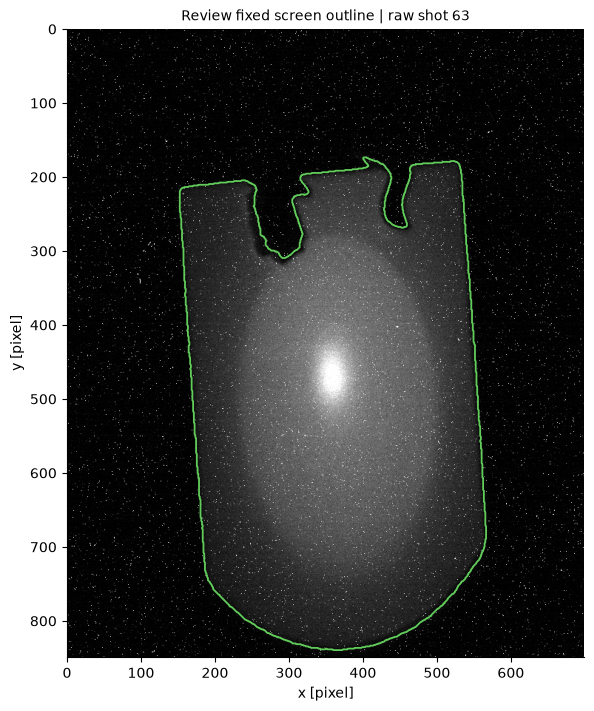

Screen outline: automatic outline proposal; level=22.6 ADU | source row: 1922


,row_id,shot_number,roi_kind,assignment,center_x,center_y,radius_x,radius_y,angle_deg,broad_light_excess_adu,...,center_offset_y,ellipse_clipped_by_screen_fraction,x0,x1,y0,y1,raw_saturated_fraction_roi,n_roi,n_outside,n_excluded
0,1704,1,compact,image proposal — review,360.003110,466.382167,35.0,55.0,0.0,2.209877,...,0.0,0.000000,326,396,412,522,0.000000,6040,337382,251578
1,1715,2,halo,image proposal — review,359.623925,505.887491,150.0,220.0,0.0,72.765432,...,40.0,0.000299,210,510,286,726,0.000010,103638,337382,153980
2,1725,3,halo,image proposal — review,358.565248,504.885463,150.0,220.0,0.0,76.358025,...,40.0,0.000666,209,509,285,725,0.000039,103600,337379,154021
3,1726,4,halo,image proposal — review,358.627926,506.479724,150.0,220.0,0.0,77.160494,...,40.0,0.000309,209,509,287,727,0.000058,103657,337382,153961
4,1777,5,halo,image proposal — review,360.160211,505.361852,150.0,220.0,0.0,74.913580,...,40.0,0.000328,211,511,286,726,0.000029,103636,337382,153982


,roi_kind,assignment,shots
0,compact,image proposal — review,27
1,halo,image proposal — review,170


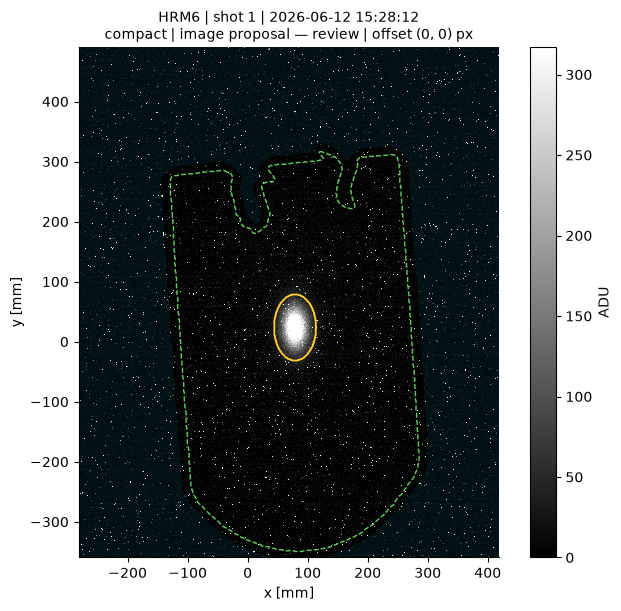

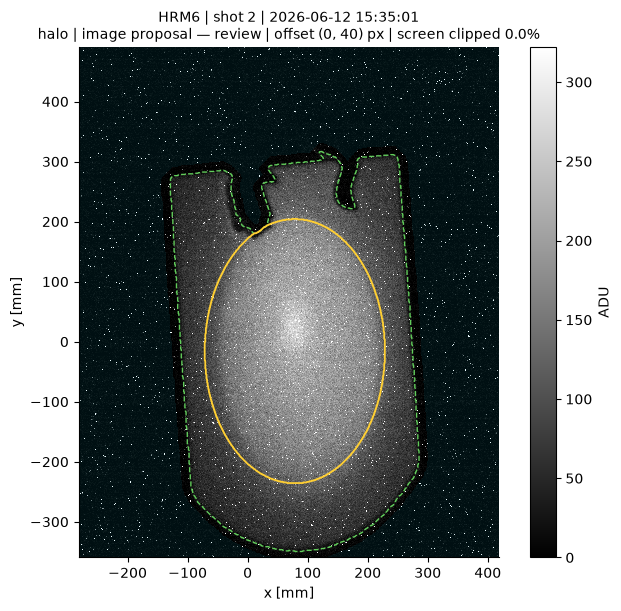

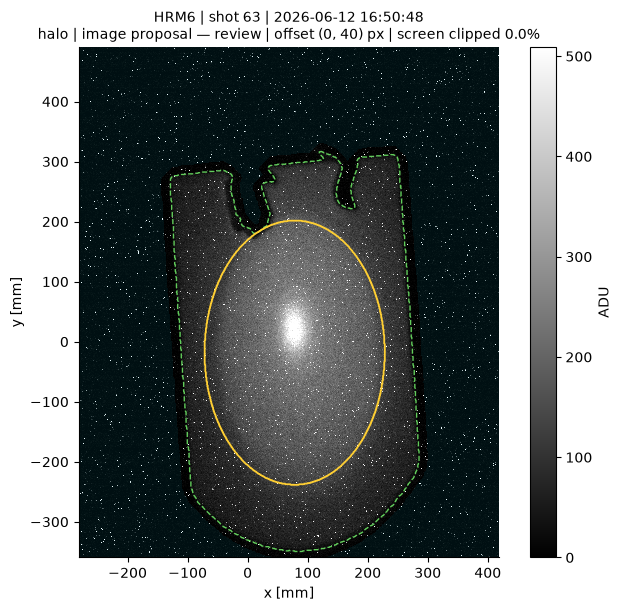

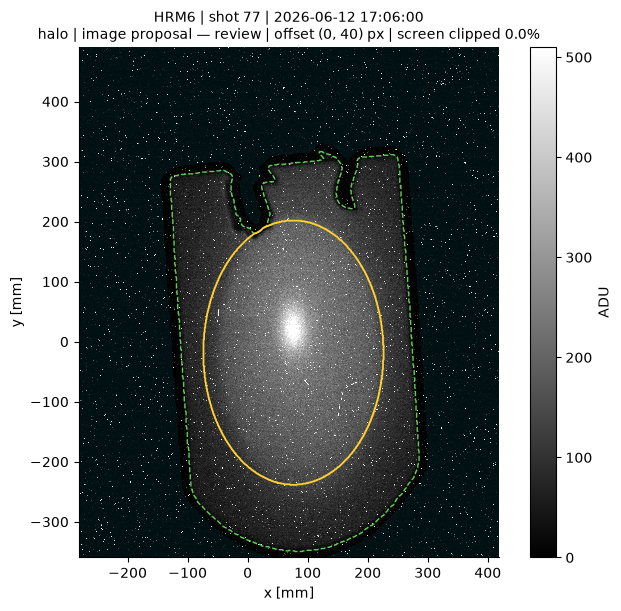

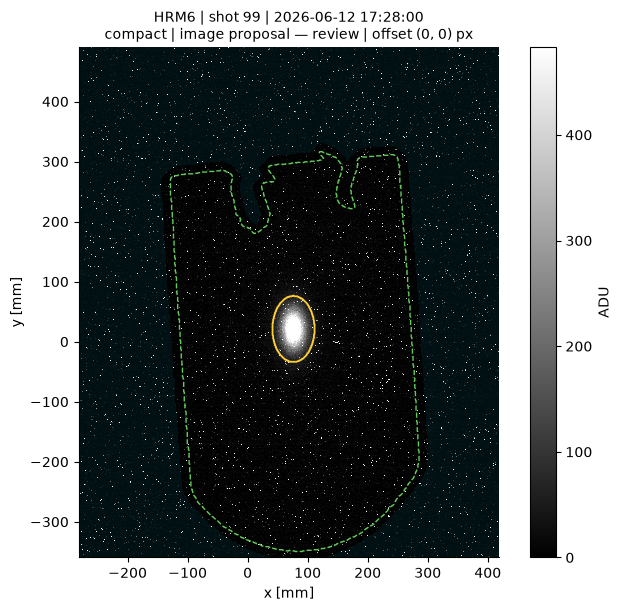

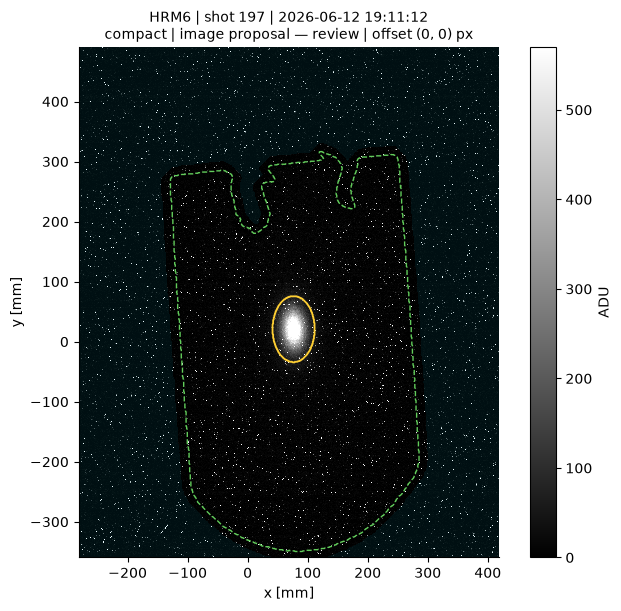

In [7]:
screen_mask, offscreen_mask, screen_source = None, None, None
if roi_mode == "ellipse_screen":
    screen_raw = load_cached(screen_reference_id)
    screen_mask, screen_source = screen_from_reference(screen_raw)
    if not screen_mask.any():
        raise ValueError("The proposed screen mask is empty; review reference/polygon")
    screen_buffer = (binary_dilation(screen_mask, iterations=int(SCREEN_GUARD_PIXELS))
                     if SCREEN_GUARD_PIXELS else screen_mask.copy())
    offscreen_mask = ~screen_buffer
    if offscreen_mask.sum() < 10:
        raise ValueError("Too little off-screen background remains; review screen outline/guard")
    lo,hi = np.percentile(screen_raw,[1,99.5]); hi=max(hi,lo+1)
    fig,ax=plt.subplots(figsize=(7,7),constrained_layout=True)
    ax.imshow(screen_raw,cmap="gray",vmin=lo,vmax=hi,origin="upper")
    ax.contour(screen_mask.astype(float),levels=[.5],colors=["#62cc5b"],linewidths=1.3)
    ax.set(xlabel="x [pixel]",ylabel="y [pixel]",
           title=f"Review fixed screen outline | raw shot {SCREEN_REFERENCE_SHOT}")
    save_plot(fig,"screen_outline_pixel_preview")
    print("Screen outline:",screen_source,"| source row:",screen_reference_id)

roi_rows=[]
for shot in beams.itertuples():
    raw=load_cached(shot.row_id)
    b=define_roi(raw,int(shot.shot_number))
    roi,outside=region_masks(raw.shape,b)
    sat=np.nan if SATURATION_ADU is None else float(np.mean(raw[roi]>=SATURATION_ADU))
    roi_rows.append(dict(row_id=int(shot.row_id),**b,raw_saturated_fraction_roi=sat,
                         n_roi=int(roi.sum()),n_outside=int(outside.sum()),
                         n_excluded=int(raw.size-roi.sum()-outside.sum())))
roi_table=pd.DataFrame(roi_rows)
roi_lookup=roi_table.set_index("row_id").to_dict("index")
display(roi_table.head())
display(roi_table.groupby(["roi_kind","assignment"]).size().rename("shots").reset_index())

preview=spread_sample(beams,min(int(QUICK_LOOK_SHOTS),len(beams))) if QUICK_LOOK_SHOTS else beams.iloc[:0]
if roi_mode=="ellipse_screen":
    representative_ids=roi_table.groupby("roi_kind",sort=False).head(1).row_id
    extra=beams.loc[beams.row_id.isin(representative_ids) |
                    beams.shot_number.isin([SCREEN_REFERENCE_SHOT]+list(ROI_EXTRA_PREVIEW_SHOTS))]
    preview=pd.concat([preview,extra]).drop_duplicates("row_id").sort_values("shot_number")
if SHOW_ALL_ROI_PREVIEWS:
    preview=beams
for shot in preview.itertuples():
    raw=load_cached(shot.row_id)
    b=roi_lookup[shot.row_id]
    lo,hi=np.percentile(raw,[1,99.5]);hi=max(hi,lo+1)
    label=f"{b['roi_kind']} | {b['assignment']}"
    if b["roi_method"]=="ellipse_screen":
        label+=f" | offset ({b['center_offset_x']:g}, {b['center_offset_y']:g}) px"
        if b["ellipse_beyond_screen"]:
            label+=f" | screen clipped {100*b['ellipse_clipped_by_screen_fraction']:.1f}%"
    fig,ax=plt.subplots(figsize=(7,6),constrained_layout=True)
    art=draw_image(ax,raw,f"{CAMERA_NAME.removesuffix('_g01')} | shot {shot.shot_number} | {shot.timestamp:%Y-%m-%d %H:%M:%S}\n{label}",
                   lo,hi,bounds=b)
    fig.colorbar(art,ax=ax,label="ADU")
    save_plot(fig,f"roi_preview_shot_{shot.shot_number:04d}")


## 7. Construct the median references and evaluate held-out backgrounds

The estimator is $M(p)=\operatorname{median}_{k=1,\ldots,N} B_k(p)$. Even-N medians can have half-ADU values;
they are kept as floating point. No rounding to integer, no percentile clipping, and no negative clipping are applied.

The scalar baseline subtracts the image's own scalar median: for a no-beam image it uses the full image;
for a beam shot it uses the fixed outside region. This is a practical pedestal-correction comparator, not an
independent background measurement. A constant subtraction leaves CNR unchanged algebraically, while it can
reduce RMS about zero. A useful pixel-wise reference should be assessed relative to this simpler option too.

Background validation has no beam ROI: all pixels are used because there is no desired beam light to exclude.
The median RMSE ranking is based only on selection frames, with ties ordered by config_id for reproducibility.

In [8]:
references = {}
for i, plan in enumerate(plans, 1):
    cid = plan["config_id"]
    if plan["alias_of"] is not None:
        references[cid] = references[plan["alias_of"]]
        print(f"{cid}: identical membership to {plan['alias_of']}; reused reference", flush=True)
        continue
    # One stack at a time; overwrite_input allows NumPy to reuse the stack for its median partition.
    estimated_gib = (plan["n_backgrounds"]+4)*np.prod(canonical_shape)*4/(1024**3)
    if estimated_gib > MAX_STACK_GIB:
        raise MemoryError(f"{cid}: estimated {estimated_gib:.2f} GiB exceeds MAX_STACK_GIB. Reduce N or raise the explicit limit.")
    stack = np.empty((plan["n_backgrounds"], *canonical_shape), dtype=np.float32)
    for j, rid in enumerate(plan["row_ids"]):
        stack[j] = load_cached(rid)
    references[cid] = np.median(stack, axis=0, overwrite_input=True).astype(np.float32)
    del stack
    gc.collect()
    if SAVE_RESULTS and SAVE_MEDIAN_ARRAYS:
        np.save(RUN_DIR / "median_references" / f"{cid}.npy", references[cid], allow_pickle=False)
    print(f"Built {i}/{len(plans)}: {cid}", flush=True)

validation_rows = []
for v in validation.itertuples():
    raw = load_cached(v.row_id)
    values = {"raw": raw, "scalar_offset": raw-np.median(raw)}
    # Keep one corrected image at a time.
    for method in ["raw", "scalar_offset"]+list(references):
        residual = values[method] if method in values else raw-references[method]
        s = distribution_stats(residual)
        validation_rows.append(dict(row_id=int(v.row_id), timestamp=v.timestamp, subset=v.subset,
                                    method=method, rmse=s["rms"], **s))
validation_metrics = pd.DataFrame(validation_rows)
chosen_id, ranking = None, pd.DataFrame()
if len(validation_metrics) and validation.subset.eq("selection").any():
    ranking = (validation_metrics.loc[validation_metrics.subset.eq("selection") & validation_metrics.method.isin(references)]
               .groupby("method").agg(selection_median_rmse=("rmse","median"), n_images=("row_id","size"))
               .reset_index().sort_values(["selection_median_rmse","method"]).reset_index(drop=True))
    chosen_id = ranking.method.iloc[0]
    print("Reference selected using no-beam selection RMSE:", chosen_id)
    display(ranking)
else:
    print("No reference selected: fewer than four validation images. Candidate/beam comparisons remain exploratory.")
shown_id = SHOW_REFERENCE or chosen_id or plans[0]["config_id"]
if shown_id not in references:
    raise KeyError(f"SHOW_REFERENCE={shown_id!r} is not an available config_id")
print("Reference used in detailed image examples:", shown_id)

Built 1/18: prior_W6h_N10
Built 2/18: prior_W6h_N25
Built 3/18: prior_W6h_N50
Built 4/18: prior_W24h_N10
Built 5/18: prior_W24h_N25
Built 6/18: prior_W24h_N50
Built 7/18: prior_W48h_N10
Built 8/18: prior_W48h_N25
Built 9/18: prior_W48h_N50
Built 10/18: offline_W6h_N10
Built 11/18: offline_W6h_N25
Built 12/18: offline_W6h_N50
Built 13/18: offline_W24h_N10
Built 14/18: offline_W24h_N25
Built 15/18: offline_W24h_N50
Built 16/18: offline_W48h_N10
Built 17/18: offline_W48h_N25
Built 18/18: offline_W48h_N50
Reference selected using no-beam selection RMSE: offline_W24h_N25


,method,selection_median_rmse,n_images
0,offline_W24h_N25,29.572871,10
1,offline_W24h_N50,29.788299,10
2,offline_W24h_N10,29.856912,10
3,offline_W48h_N10,35.962939,10
4,offline_W48h_N25,37.233110,10
5,offline_W48h_N50,37.278281,10
6,prior_W6h_N50,37.824631,10
7,prior_W6h_N25,37.842598,10
8,prior_W6h_N10,37.878976,10
9,prior_W24h_N10,41.301198,10


Reference used in detailed image examples: offline_W24h_N25


## 8. Apply every candidate to the same beam shots

Raw measurements are calculated once per shot. All corrected measurements use the same stored raw ROI/outside
mask. Signed subtraction is performed in floating point, so unsigned underflow cannot occur. Beam brightness cuts,
intensity-based pixel rejection, image renormalisation and re-centering on the corrected image are not used.

The ROI sum, mean contrast, reference contribution and negative fractions are saved as well as the ratios. A ratio
alone is insufficient: confirm that its change comes from a reduced background denominator and check how its
estimated signal numerator changes. Photon shot noise, spill outside the ROI, saturation and beam-induced
transient events remain possible limitations.

In [9]:
beam_rows = []
started = time.monotonic()
for i, shot in enumerate(beams.itertuples(), 1):
    raw = load_cached(shot.row_id)
    bounds = roi_lookup[shot.row_id]
    roi, outside = region_masks(raw.shape, bounds)
    scalar = float(np.median(raw[outside]))
    for method in ["raw", "scalar_offset"]+list(references):
        correction = 0.0 if method == "raw" else (scalar if method == "scalar_offset" else references[method])
        measured = raw.astype(np.float64)-correction
        stats = image_metrics(measured, roi, outside)
        removed_sum = (float(correction)*roi.sum() if np.ndim(correction) == 0
                       else float(np.sum(correction[roi], dtype=np.float64)))
        beam_rows.append(dict(row_id=int(shot.row_id), shot_number=int(shot.shot_number), timestamp=shot.timestamp,
                              method=method, roi_method=bounds["roi_method"], roi_kind=bounds["roi_kind"],
                              roi_assignment=bounds["assignment"], reference_removed_roi_sum=removed_sum,
                              raw_saturated_fraction_roi=bounds["raw_saturated_fraction_roi"],
                              **{col:float(meta_lookup.loc[shot.row_id,col]) for col in BCT_COLUMNS}, **stats))
    if i % 10 == 0 or i == len(beams):
        print(f"Measured {i}/{len(beams)} beam shots; {len(references)} median candidates; {time.monotonic()-started:.1f} s", flush=True)
beam_metrics = pd.DataFrame(beam_rows)
display(beam_metrics.head())

Measured 10/197 beam shots; 18 median candidates; 5.6 s
Measured 20/197 beam shots; 18 median candidates; 11.4 s
Measured 30/197 beam shots; 18 median candidates; 17.0 s
Measured 40/197 beam shots; 18 median candidates; 22.9 s
Measured 50/197 beam shots; 18 median candidates; 28.6 s
Measured 60/197 beam shots; 18 median candidates; 34.4 s
Measured 70/197 beam shots; 18 median candidates; 40.2 s
Measured 80/197 beam shots; 18 median candidates; 45.7 s
Measured 90/197 beam shots; 18 median candidates; 51.3 s
Measured 100/197 beam shots; 18 median candidates; 56.6 s
Measured 110/197 beam shots; 18 median candidates; 61.9 s
Measured 120/197 beam shots; 18 median candidates; 67.7 s
Measured 130/197 beam shots; 18 median candidates; 73.4 s
Measured 140/197 beam shots; 18 median candidates; 79.2 s
Measured 150/197 beam shots; 18 median candidates; 85.0 s
Measured 160/197 beam shots; 18 median candidates; 90.8 s
Measured 170/197 beam shots; 18 median candidates; 96.6 s
Measured 180/197 beam sh

,row_id,shot_number,timestamp,method,roi_method,roi_kind,roi_assignment,reference_removed_roi_sum,raw_saturated_fraction_roi,TT60.BCTFI.610225:TOTAL_INTENSITY,...,n_roi,contrast,cnr,integrated_snr_std,contrast_over_rms,sbr,legacy_peak_snr_mad,legacy_integrated_positive_snr_mad,roi_negative_fraction,roi_lower01
0,1704,1,2026-06-12 15:28:12.135000064+02:00,raw,ellipse_screen,compact,image proposal — review,0.0,0.0,3.981269e+11,...,6040,150.970846,3.017249,234.492853,2.984743,20.388651,868.744098,8249.575229,0.000000,22.000
1,1704,1,2026-06-12 15:28:12.135000064+02:00,scalar_offset,ellipse_screen,compact,image proposal — review,6040.0,0.0,3.981269e+11,...,6040,150.970846,3.017249,234.492853,2.992831,23.572064,868.744098,8249.575229,0.000000,21.000
2,1704,1,2026-06-12 15:28:12.135000064+02:00,prior_W6h_N10,ellipse_screen,compact,image proposal — review,34820.5,0.0,3.981269e+11,...,6040,150.736286,6.545549,508.703259,6.523978,80.425837,251.450155,3200.536432,0.000993,20.695
3,1704,1,2026-06-12 15:28:12.135000064+02:00,prior_W6h_N25,ellipse_screen,compact,image proposal — review,32441.0,0.0,3.981269e+11,...,6040,150.776503,6.572251,510.778469,6.541475,67.674474,315.661675,4010.878927,0.000993,21.000
4,1704,1,2026-06-12 15:28:12.135000064+02:00,prior_W6h_N50,ellipse_screen,compact,image proposal — review,32130.5,0.0,3.981269e+11,...,6040,150.700771,6.580150,511.392397,6.545633,63.988944,315.324430,4012.321771,0.000993,21.000


## 9. Paired summaries: how often, how much, and with what numerator?

For ratios where larger is better, gain = corrected/raw only when the raw value is strictly positive and the
corrected value is finite. Signed differences are reported separately for every finite pair. For background burden,
reduction = 100 × (raw − corrected)/raw. Its value can be negative. No minimum denominator is inserted.

The tables report the numbers of valid, undefined, improved, worse and tied pairs. Percent improved uses valid
finite pairs; coverage is shown beside it. These are descriptive fractions, not confidence levels. A median of per-shot
gains differs from a ratio of two sample medians. No p-value or claim of statistical significance is inferred from these summaries.

The integrated standard-deviation SNR is a scaled CNR; agreement between them is not independent corroboration.
Configurable grid cells are not repeated independent experiments. The validation-selected reference should remain
the nominated reference when reading the beam results, even if another grid cell has a larger exploratory gain.

In [10]:
RATIO_METRICS = ["cnr", "integrated_snr_std", "contrast_over_rms", "sbr",
                 "legacy_peak_snr_mad", "legacy_integrated_positive_snr_mad"]
BURDEN_METRICS = ["outside_rms", "outside_std", "outside_tail99", "outside_tail999", "outside_abs99"]

def paired_summary(frame, metric, higher_better=True):
    wide = frame.pivot(index="row_id", columns="method", values=metric)
    rows = []
    raw = wide["raw"].to_numpy(dtype=float)
    for method in wide.columns.drop("raw"):
        corrected = wide[method].to_numpy(dtype=float)
        finite = np.isfinite(raw) & np.isfinite(corrected)
        difference = corrected[finite]-raw[finite]
        tie = np.isclose(corrected[finite], raw[finite], rtol=1e-9, atol=1e-10)
        improved = ((difference > 0) if higher_better else (difference < 0)) & ~tie
        worse = ((difference < 0) if higher_better else (difference > 0)) & ~tie
        ratio_ok = finite & (raw > 0)
        gains = corrected[ratio_ok]/raw[ratio_ok]
        rows.append(dict(method=method, metric=metric, n_total=len(raw), n_finite_pairs=int(finite.sum()),
                          n_undefined_pairs=int((~finite).sum()), n_improved=int(improved.sum()), n_worse=int(worse.sum()),
                          n_tied=int(tie.sum()), percent_improved=100*improved.mean() if finite.any() else np.nan,
                          median_raw=float(np.median(raw[finite])) if finite.any() else np.nan,
                          median_corrected=float(np.median(corrected[finite])) if finite.any() else np.nan,
                          median_signed_change=float(np.median(difference)) if finite.any() else np.nan,
                          n_valid_gain=int(ratio_ok.sum()), median_gain=float(np.median(gains)) if gains.size else np.nan,
                          gain_q25=float(np.percentile(gains,25)) if gains.size else np.nan,
                          gain_q75=float(np.percentile(gains,75)) if gains.size else np.nan,
                          median_reduction_percent=float(np.median(100*(1-gains))) if gains.size else np.nan))
    return pd.DataFrame(rows)

beam_ratio_summary = pd.concat([paired_summary(beam_metrics, m) for m in RATIO_METRICS], ignore_index=True)
beam_burden_summary = pd.concat([paired_summary(beam_metrics, m, False) for m in BURDEN_METRICS], ignore_index=True)
print("All candidate CNR gains — exploratory beam comparison, not the validation-selection rule:")
all_candidate_cnr = (beam_ratio_summary.loc[beam_ratio_summary.metric.eq("cnr") & beam_ratio_summary.method.isin(references)]
    .merge(plan_table, left_on="method", right_on="config_id")
    .sort_values("median_gain", ascending=False))
display(all_candidate_cnr[["method","timing_label","window_hours","n_backgrounds","n_total","n_valid_gain",
                           "median_gain","gain_q25","gain_q75","percent_improved","n_worse","n_tied"]])
print("All ratio gains — supplementary ratios may be undefined; use pair counts in the complete summaries:")
display(beam_ratio_summary.pivot(index="method",columns="metric",values="median_gain"))
headline_methods = ["scalar_offset", shown_id]
print("Paired beam ratios — detailed reference and scalar baseline:")
display(beam_ratio_summary.loc[beam_ratio_summary.method.isin(headline_methods),
    ["method","metric","n_total","n_finite_pairs","n_undefined_pairs","median_gain","gain_q25","gain_q75",
     "n_improved","n_worse","n_tied","percent_improved"]])
print("Background burden in beam-image outside regions — positive reduction means lower burden:")
display(beam_burden_summary.loc[beam_burden_summary.method.isin(headline_methods),
    ["method","metric","n_finite_pairs","median_raw","median_corrected","median_reduction_percent","percent_improved"]])

validation_summary = pd.DataFrame()
if len(validation_metrics):
    validation_summary = (validation_metrics.groupby(["subset","method"], sort=True)
        .agg(n_images=("row_id","size"), median_rmse=("rmse","median"), median_signed_mean=("mean","median"),
             median_std=("std","median"), median_tail99=("tail99","median"),
             median_tail999=("tail999","median"), median_abs99=("abs99","median"), median_lower01=("lower01","median"))
        .reset_index())
    print("No-beam validation: all methods, separately for selection and check images:")
    display(validation_summary)
    check = validation_summary.loc[validation_summary.subset.eq("check")]
    if len(check) and chosen_id is not None:
        key = check.set_index("method").median_rmse
        if key[chosen_id] >= key["scalar_offset"]:
            print("On the later check backgrounds, the chosen pixel-wise median does not beat scalar correction by median RMSE.")
        if key[chosen_id] >= key["raw"]:
            print("On the later check backgrounds, the chosen reference does not reduce median RMSE relative to raw.")

print("Numerator and residual checks — read these alongside gains:")
display(beam_metrics.groupby("method").agg(n_shots=("row_id","size"), median_contrast=("contrast","median"),
    median_roi_sum=("roi_sum","median"), median_outside_mean=("outside_mean","median"),
    median_outside_lower01=("outside_lower01","median"), median_outside_abs99=("outside_abs99","median"),
    median_negative_fraction_roi=("roi_negative_fraction","median"),
    median_raw_saturated_fraction_roi=("raw_saturated_fraction_roi","median")))

All candidate CNR gains — exploratory beam comparison, not the validation-selection rule:


,method,timing_label,window_hours,n_backgrounds,n_total,n_valid_gain,median_gain,gain_q25,gain_q75,percent_improved,n_worse,n_tied
8,offline_W6h_N50,offline,6.0,50,197,197,1.635846,1.341151,1.813539,94.416244,11,0
7,offline_W6h_N25,offline,6.0,25,197,197,1.634855,1.342543,1.812128,94.416244,11,0
6,offline_W6h_N10,offline,6.0,10,197,197,1.616869,1.336347,1.895250,93.908629,12,0
0,offline_W24h_N10,offline,24.0,10,197,197,1.489068,1.429793,1.820293,100.000000,0,0
2,offline_W24h_N50,offline,24.0,50,197,197,1.483002,1.422366,1.820777,100.000000,0,0
1,offline_W24h_N25,offline,24.0,25,197,197,1.464006,1.407865,1.815546,100.000000,0,0
3,offline_W48h_N10,offline,48.0,10,197,197,1.251679,1.191219,1.310154,100.000000,0,0
5,offline_W48h_N50,offline,48.0,50,197,197,1.231374,1.176804,1.283171,100.000000,0,0
4,offline_W48h_N25,offline,48.0,25,197,197,1.230854,1.176203,1.282772,100.000000,0,0
17,prior_W6h_N50,prior,6.0,50,197,197,1.225982,1.171008,1.275676,100.000000,0,0


All ratio gains — supplementary ratios may be undefined; use pair counts in the complete summaries:


metric,cnr,contrast_over_rms,integrated_snr_std,legacy_integrated_positive_snr_mad,legacy_peak_snr_mad,sbr
method,,,,,,
offline_W24h_N10,1.489068,1.499725,1.489068,0.648632,0.666992,3.021605
offline_W24h_N25,1.464006,1.473945,1.464006,0.650025,0.666830,2.681043
offline_W24h_N50,1.483002,1.492492,1.483002,0.778457,0.800098,2.661440
offline_W48h_N10,1.251679,1.259542,1.251679,0.654207,0.666911,2.005563
offline_W48h_N25,1.230854,1.237973,1.230854,0.654938,0.666830,1.871730
offline_W48h_N50,1.231374,1.238209,1.231374,0.784549,0.799707,1.823518
offline_W6h_N10,1.616869,1.634217,1.616869,0.644327,0.666911,4.271868
offline_W6h_N25,1.634855,1.649347,1.634855,0.645950,0.666830,4.542960
offline_W6h_N50,1.635846,1.651537,1.635846,0.774499,0.800098,4.313049


Paired beam ratios — detailed reference and scalar baseline:


,method,metric,n_total,n_finite_pairs,n_undefined_pairs,median_gain,gain_q25,gain_q75,n_improved,n_worse,n_tied,percent_improved
1,offline_W24h_N25,cnr,197,197,0,1.464006,1.407865,1.815546,197,0,0,100.000000
18,scalar_offset,cnr,197,197,0,1.000000,1.000000,1.000000,0,0,197,0.000000
20,offline_W24h_N25,integrated_snr_std,197,197,0,1.464006,1.407865,1.815546,197,0,0,100.000000
37,scalar_offset,integrated_snr_std,197,197,0,1.000000,1.000000,1.000000,0,0,197,0.000000
39,offline_W24h_N25,contrast_over_rms,197,197,0,1.473945,1.417087,1.826919,197,0,0,100.000000
56,scalar_offset,contrast_over_rms,197,197,0,1.003434,1.003266,1.003656,197,0,0,100.000000
58,offline_W24h_N25,sbr,197,196,1,2.681043,2.222293,3.071216,196,0,0,100.000000
75,scalar_offset,sbr,197,197,0,1.214621,1.185013,1.240235,197,0,0,100.000000
77,offline_W24h_N25,legacy_peak_snr_mad,197,197,0,0.666830,0.666504,0.666992,1,195,1,0.507614
94,scalar_offset,legacy_peak_snr_mad,197,197,0,1.000000,1.000000,1.000000,0,0,197,0.000000


... (2 outputs left out)

No-beam validation: all methods, separately for selection and check images:


,subset,method,n_images,median_rmse,median_signed_mean,median_std,median_tail99,median_tail999,median_abs99,median_lower01
0,check,offline_W24h_N10,10,22.631465,2.420314,22.506494,22.7500,235.50100,28.0000,-10.00
1,check,offline_W24h_N25,10,26.145192,2.881328,25.990918,22.5000,234.50000,27.5000,-8.00
2,check,offline_W24h_N50,10,23.930764,2.913062,23.758275,22.2500,217.50000,27.0000,-8.00
3,check,offline_W48h_N10,10,48.159294,4.279772,47.972685,32.7500,657.00050,45.0000,-9.00
4,check,offline_W48h_N25,10,49.035561,4.649222,48.818863,31.5000,669.50100,43.5000,-7.00
5,check,offline_W48h_N50,10,49.077342,4.814250,48.845001,31.0000,669.25150,42.7500,-6.50
6,check,offline_W6h_N10,10,34.407951,0.434473,34.354322,20.5000,124.25025,37.2500,-18.25
7,check,offline_W6h_N25,10,34.336887,0.950687,34.328386,21.0000,119.00000,33.0000,-15.50
8,check,offline_W6h_N50,10,34.308857,1.032999,34.298419,20.5000,116.00000,32.2500,-15.50
9,check,prior_W24h_N10,10,52.244941,4.607871,52.045251,45.0000,723.75050,67.0000,-9.50


Numerator and residual checks — read these alongside gains:


,n_shots,median_contrast,median_roi_sum,median_outside_mean,median_outside_lower01,median_outside_abs99,median_negative_fraction_roi,median_raw_saturated_fraction_roi
method,,,,,,,,
offline_W24h_N10,197,213.116537,21875585.0,3.607172,-9.5,41.000,0.000347,0.000048
offline_W24h_N25,197,212.843364,21924470.0,4.067152,-8.0,36.000,0.000289,0.000048
offline_W24h_N50,197,212.894336,21926470.0,4.096961,-7.5,38.000,0.000331,0.000048
offline_W48h_N10,197,213.015427,22070333.5,5.447894,-8.5,51.500,0.000164,0.000048
offline_W48h_N25,197,212.951335,22101616.0,5.835030,-7.0,50.000,0.000154,0.000048
offline_W48h_N50,197,212.973357,22121581.5,5.990379,-6.0,49.000,0.000154,0.000048
offline_W6h_N10,197,212.339810,21645446.5,1.757120,-19.0,45.000,0.002276,0.000048
offline_W6h_N25,197,212.372951,21701679.0,2.268574,-16.0,42.000,0.001997,0.000048
offline_W6h_N50,197,212.167037,21693362.0,2.396204,-16.0,41.595,0.002036,0.000048


## 10. Configuration plots and paired per-shot changes

Each heatmap cell contains the same beam shots. White/missing cells are unavailable configurations or undefined
values. The heatmap annotates a gain, while the summary CSV contains valid-pair counts and improvement fractions.
Black/grey points on paired plots are not dropped when they deteriorate.

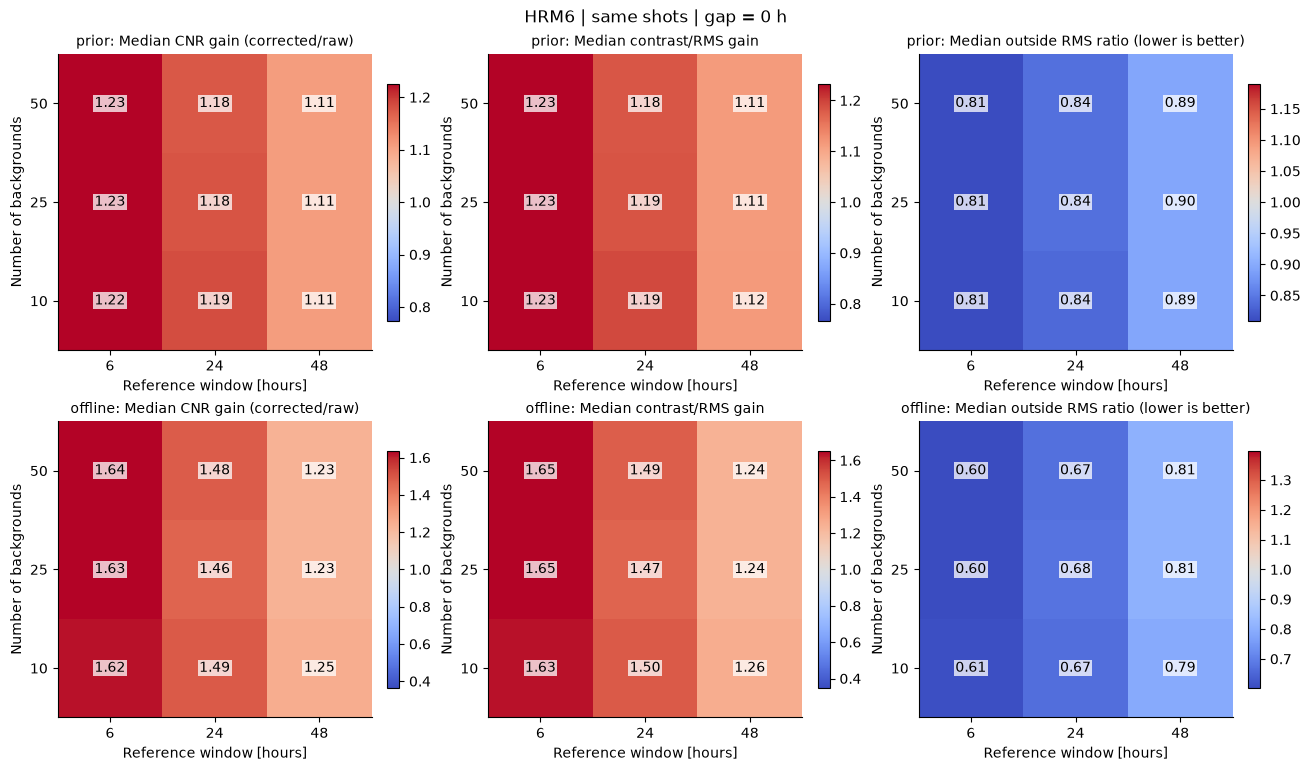

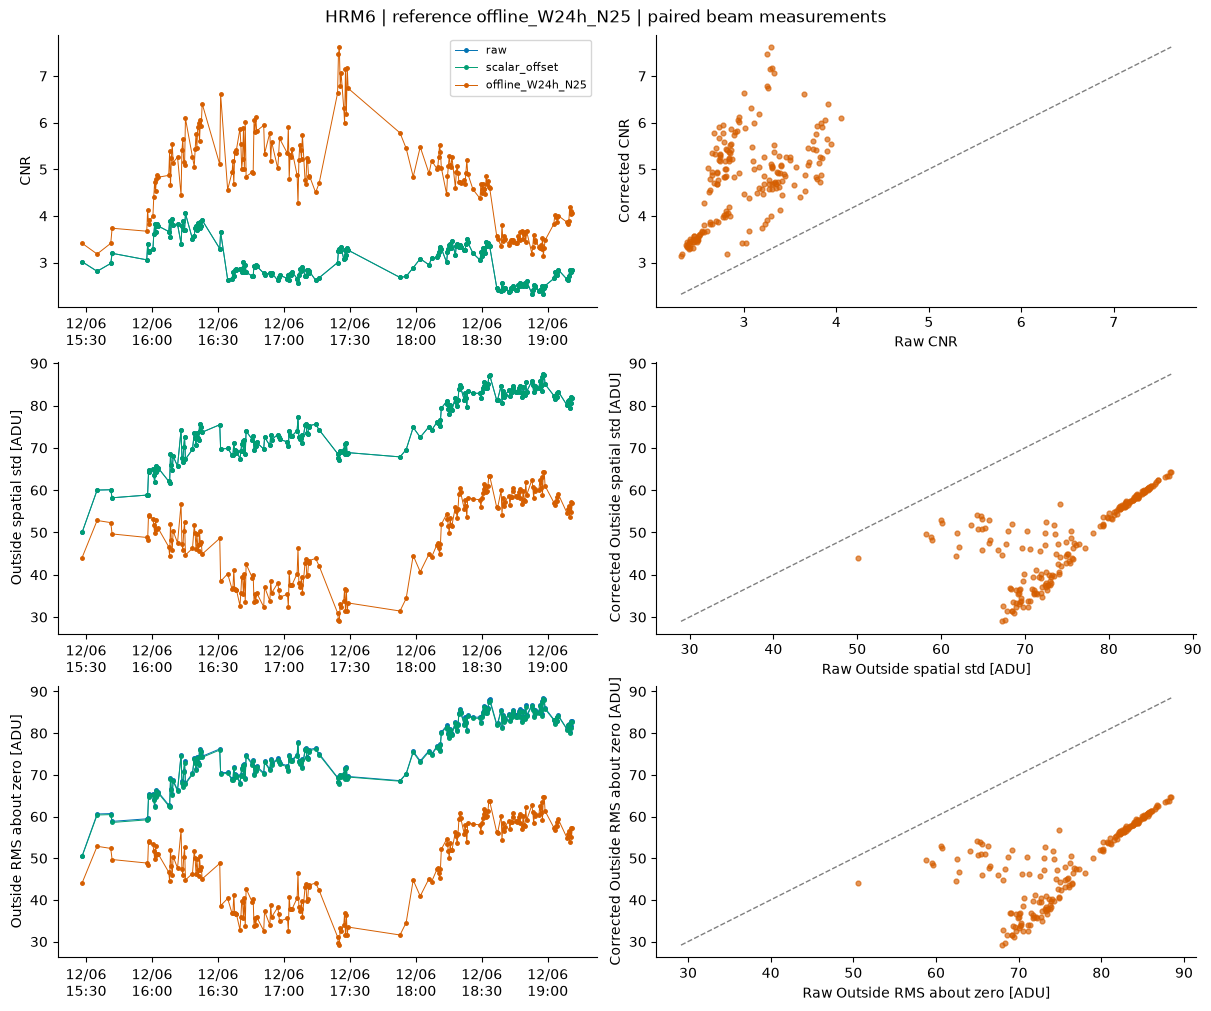

In [11]:
def config_heatmap(ax, summary, metric, value, title, end_mode, cmap="viridis", centre_one=False):
    f = summary.loc[summary.metric.eq(metric)].merge(plan_table, left_on="method", right_on="config_id")
    f = f.loc[f.reference_end_mode.eq(end_mode)]
    table = (f.pivot(index="n_backgrounds", columns="window_hours", values=value)
             .reindex(index=sorted(BACKGROUND_COUNTS), columns=sorted(float(w) for w in BACKGROUND_WINDOW_HOURS)))
    a = table.to_numpy(dtype=float)
    kwargs = {}
    if centre_one and np.isfinite(a).any():
        delta = max(float(np.nanmax(np.abs(a-1))), .02)
        kwargs = dict(vmin=1-delta,vmax=1+delta)
    im = ax.imshow(np.ma.masked_invalid(a), origin="lower", aspect="auto", cmap=cmap, **kwargs)
    ax.set_xticks(range(len(table.columns)), [f"{x:g}" for x in table.columns])
    ax.set_yticks(range(len(table.index)), [str(x) for x in table.index])
    ax.set_xlabel("Reference window [hours]"); ax.set_ylabel("Number of backgrounds")
    ax.set_title(title)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            ax.text(j,i, f"{a[i,j]:.2f}" if np.isfinite(a[i,j]) else "—", ha="center", va="center",
                    bbox=dict(facecolor="white",alpha=.75,edgecolor="none",pad=1))
    return im

fig, axes = plt.subplots(len(REFERENCE_END_CHOICES),3,figsize=(13,3.8*len(REFERENCE_END_CHOICES)),squeeze=False,constrained_layout=True)
for axrow, end_mode in zip(axes, REFERENCE_END_CHOICES):
    timing = "prior" if end_mode == "analysis_start" else "offline"
    for ax, metric, title in zip(axrow, ["cnr","contrast_over_rms","outside_rms"],
                                ["Median CNR gain (corrected/raw)","Median contrast/RMS gain","Median outside RMS ratio (lower is better)"]):
        table = beam_ratio_summary if metric != "outside_rms" else beam_burden_summary
        im = config_heatmap(ax,table,metric,"median_gain",f"{timing}: {title}",end_mode,"coolwarm",True)
        fig.colorbar(im,ax=ax,shrink=.8)
fig.suptitle(f"{CAMERA_NAME.removesuffix('_g01')} | same shots | gap = {BACKGROUND_GAP_HOURS:g} h")
save_plot(fig,"configuration_grid")

focus = beam_metrics.loc[beam_metrics.method.isin(["raw","scalar_offset",shown_id])]
fig, axes = plt.subplots(3,2,figsize=(12,10),constrained_layout=True)
for axrow, metric, label in zip(axes,["cnr","outside_std","outside_rms"],["CNR","Outside spatial std [ADU]","Outside RMS about zero [ADU]"]):
    for method,colour in [("raw",RAW_COLOUR),("scalar_offset",SCALAR_COLOUR),(shown_id,CORRECTED_COLOUR)]:
        q=focus.loc[focus.method.eq(method)].sort_values("timestamp")
        axrow[0].plot(q.timestamp,q[metric],"o-",ms=2.5,lw=.7,color=colour,label=method)
    axrow[0].set_ylabel(label)
    axrow[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M",tz=T0.tzinfo))
    wide=focus.pivot(index="row_id",columns="method",values=metric)
    x,y=wide["raw"].to_numpy(),wide[shown_id].to_numpy()
    good=np.isfinite(x)&np.isfinite(y)
    axrow[1].scatter(x[good],y[good],s=12,alpha=.65,color=CORRECTED_COLOUR)
    if good.any():
        low,high=float(min(x[good].min(),y[good].min())),float(max(x[good].max(),y[good].max()))
        axrow[1].plot([low,high],[low,high],"--",color=".5",lw=1)
    axrow[1].set_xlabel(f"Raw {label}");axrow[1].set_ylabel(f"Corrected {label}")
axes[0,0].legend()
fig.suptitle(f"{CAMERA_NAME.removesuffix('_g01')} | reference {shown_id} | paired beam measurements")
save_plot(fig,"paired_beam_measurements")

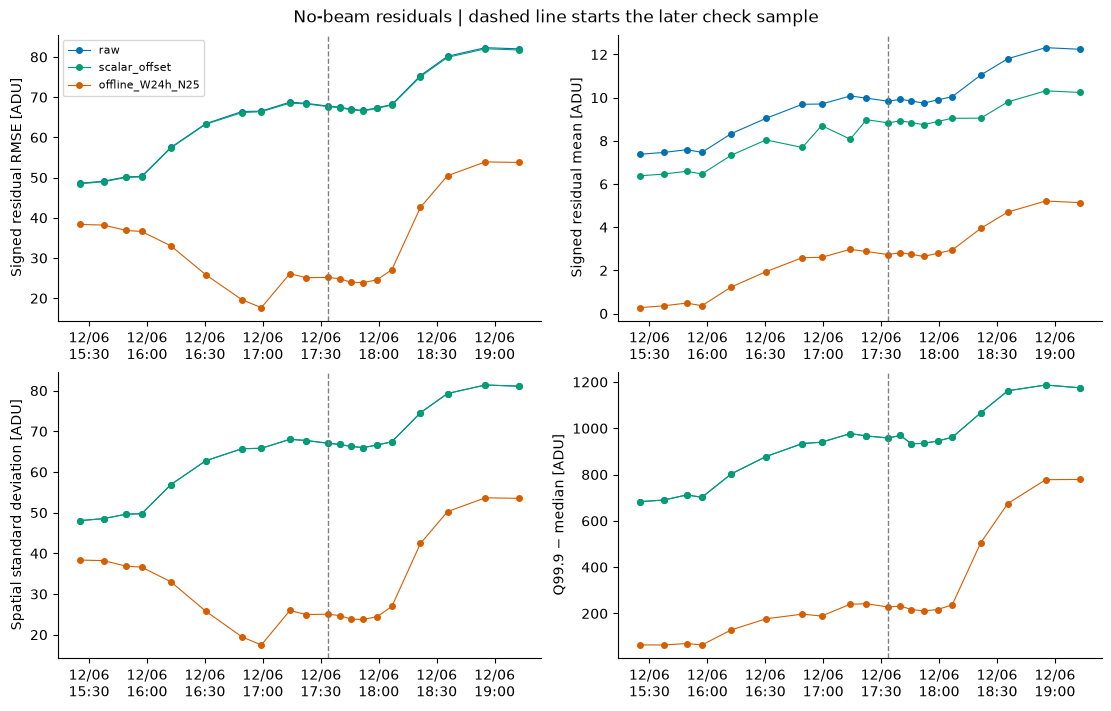

In [12]:
if len(validation_metrics):
    show_methods=["raw","scalar_offset",shown_id]
    f=validation_metrics.loc[validation_metrics.method.isin(show_methods)]
    fig,axes=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
    for ax,metric,label in zip(axes.flat,["rmse","mean","std","tail999"],
        ["Signed residual RMSE [ADU]","Signed residual mean [ADU]","Spatial standard deviation [ADU]","Q99.9 − median [ADU]"]):
        for method,colour in [("raw",RAW_COLOUR),("scalar_offset",SCALAR_COLOUR),(shown_id,CORRECTED_COLOUR)]:
            q=f.loc[f.method.eq(method)].sort_values("timestamp")
            ax.plot(q.timestamp,q[metric],"o-",ms=4,lw=.8,label=method,color=colour)
        if validation.subset.eq("check").any():
            ax.axvline(validation.loc[validation.subset.eq("check"),"timestamp"].min(),color=".5",ls="--",lw=1)
        ax.set_ylabel(label)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M",tz=T0.tzinfo))
    axes[0,0].legend()
    fig.suptitle("No-beam residuals | dashed line starts the later check sample")
    save_plot(fig,"held_out_background_validation")

## 11. Beam images, actual summed projections and outside distributions

Examples are spread through time, independently of their gains. In ellipse mode, the first available shot of each
ROI kind and the screen-reference shot are also included so compact examples cannot hide all halo cases. Raw and corrected images share the same colour
limits. The reference has its own labelled limits. Percentile limits affect display only. All metrics retain every signed value within their defined masks, including saturated and extreme coordinates.

Projections are actual sums of pixels in the same frozen signal mask, in ADU (no area normalisation).
Ellipse/screen exclusions are applied before summing; a rectangular bounding-box crop is not used as the signal mask. A change in a projection
may be removal of background or loss of signal from a mismatched reference; without truth it is not proof of either.
The outside histogram uses the combined raw/corrected/scalar range and all outside pixels in its denominator.
Underflow/overflow are counted if extreme values exceed that display range. Logarithmic percentages expose the tail.

Shot 1, raw: histogram observations outside display = 0.0498%
Shot 1, scalar offset: histogram observations outside display = 0.0498%
Shot 1, median corrected: histogram observations outside display = 0.0563%


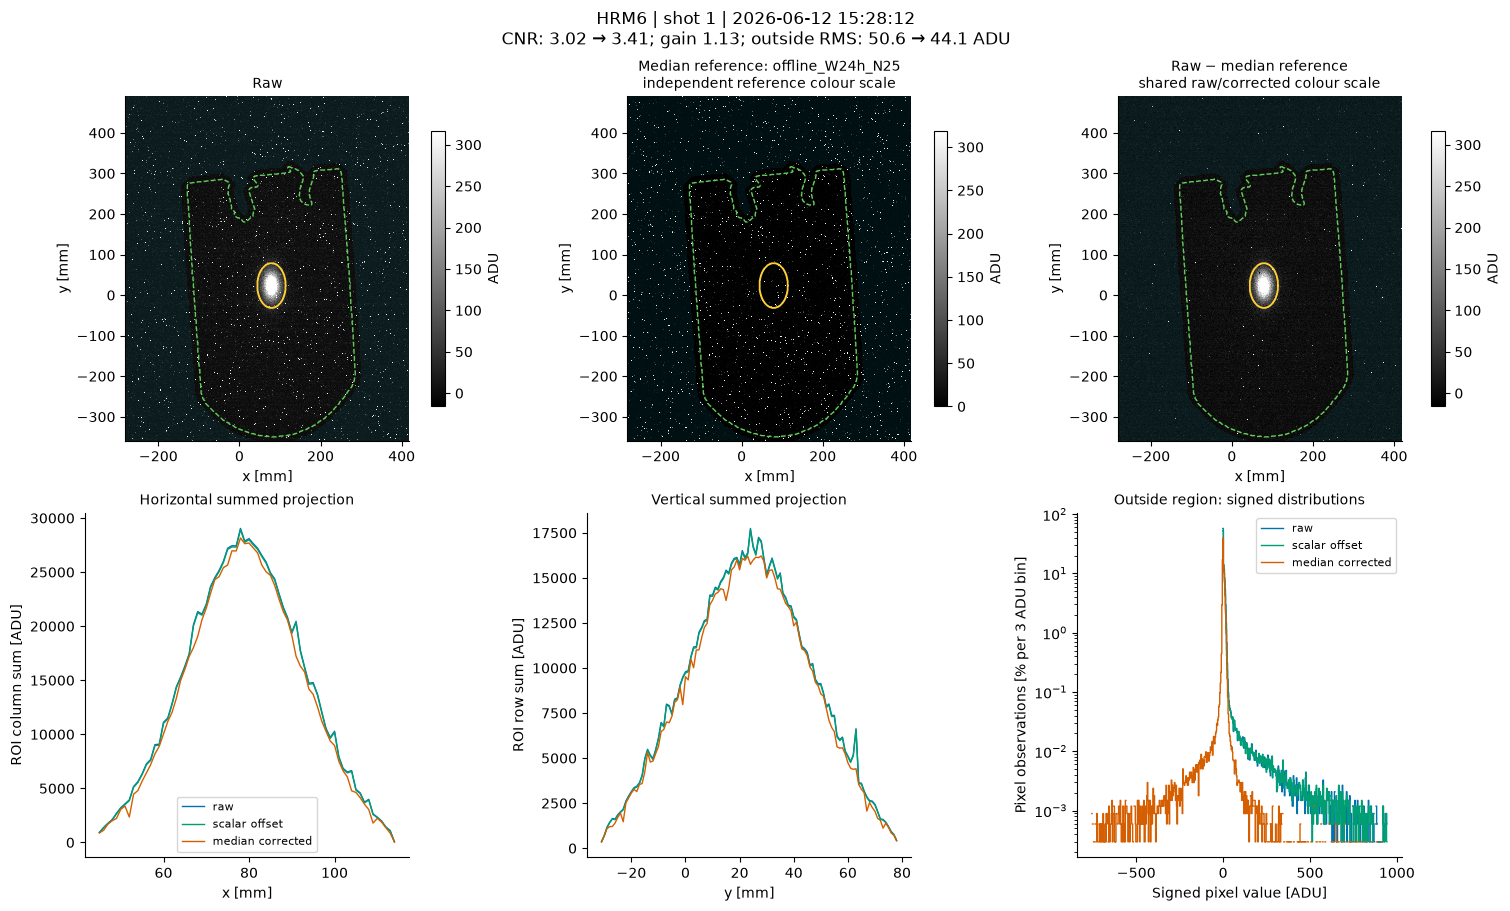

Shot 2, raw: histogram observations outside display = 0.0498%
Shot 2, scalar offset: histogram observations outside display = 0.0498%
Shot 2, median corrected: histogram observations outside display = 0.0694%


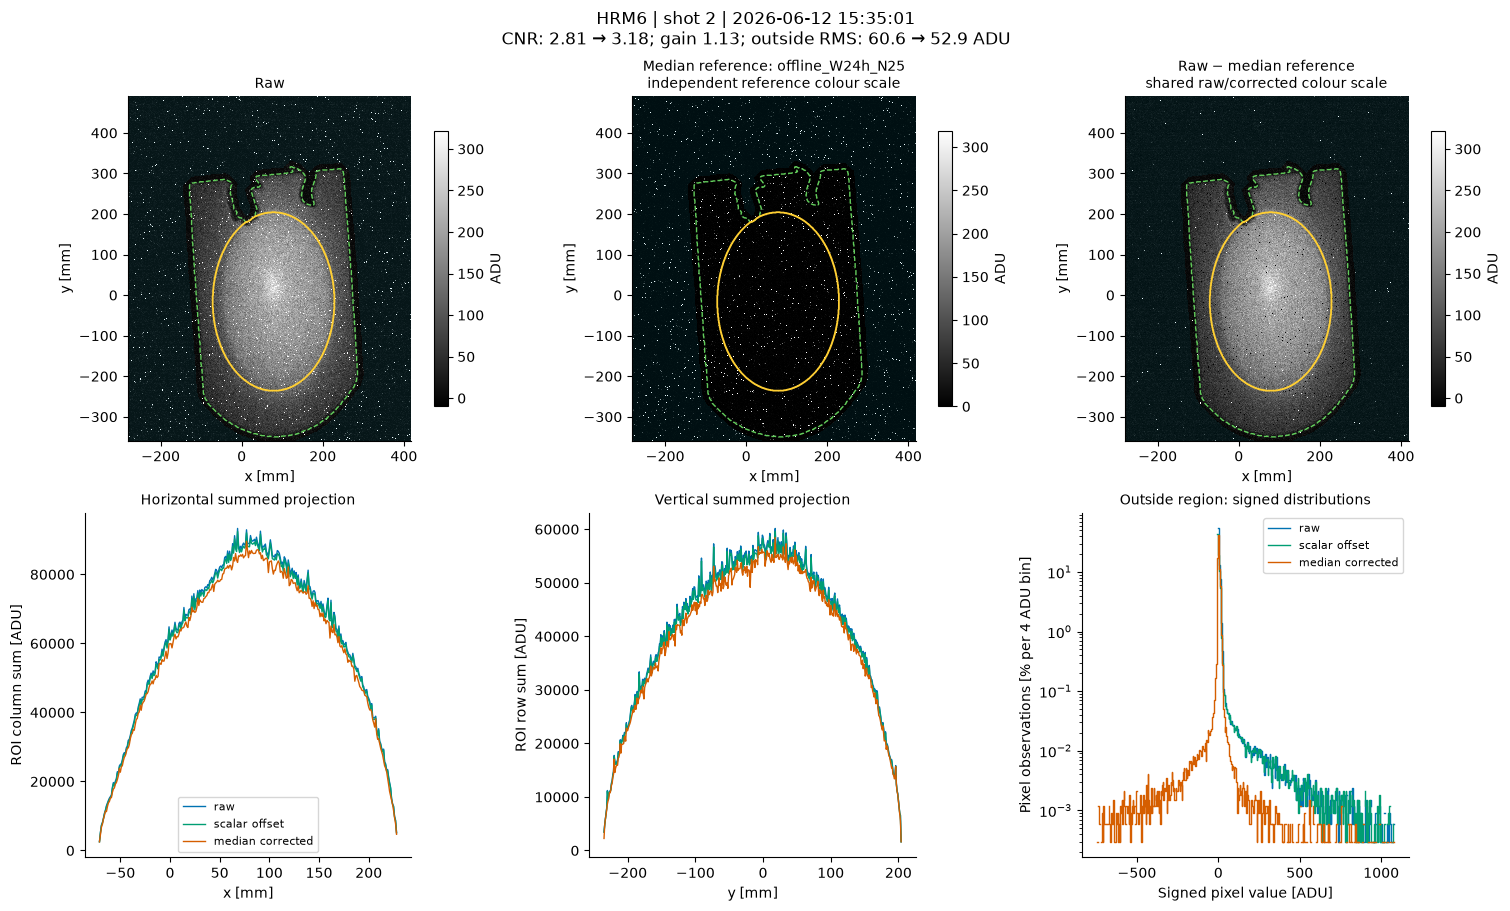

Shot 63, raw: histogram observations outside display = 0.0495%
Shot 63, scalar offset: histogram observations outside display = 0.0495%
Shot 63, median corrected: histogram observations outside display = 0.0596%


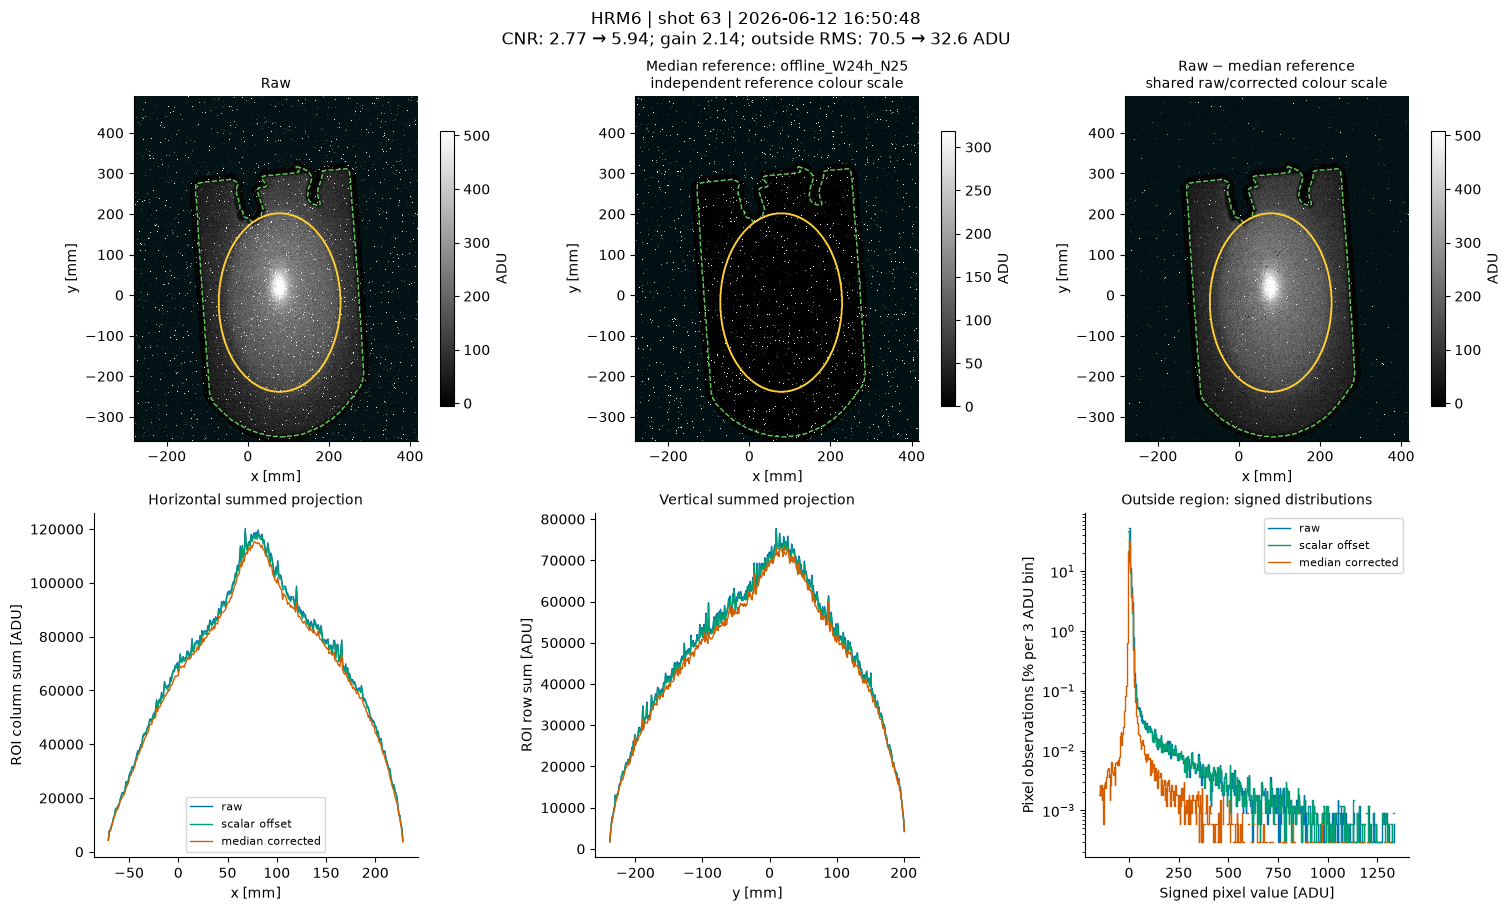

Shot 99, raw: histogram observations outside display = 0.0498%
Shot 99, scalar offset: histogram observations outside display = 0.0498%
Shot 99, median corrected: histogram observations outside display = 0.0575%


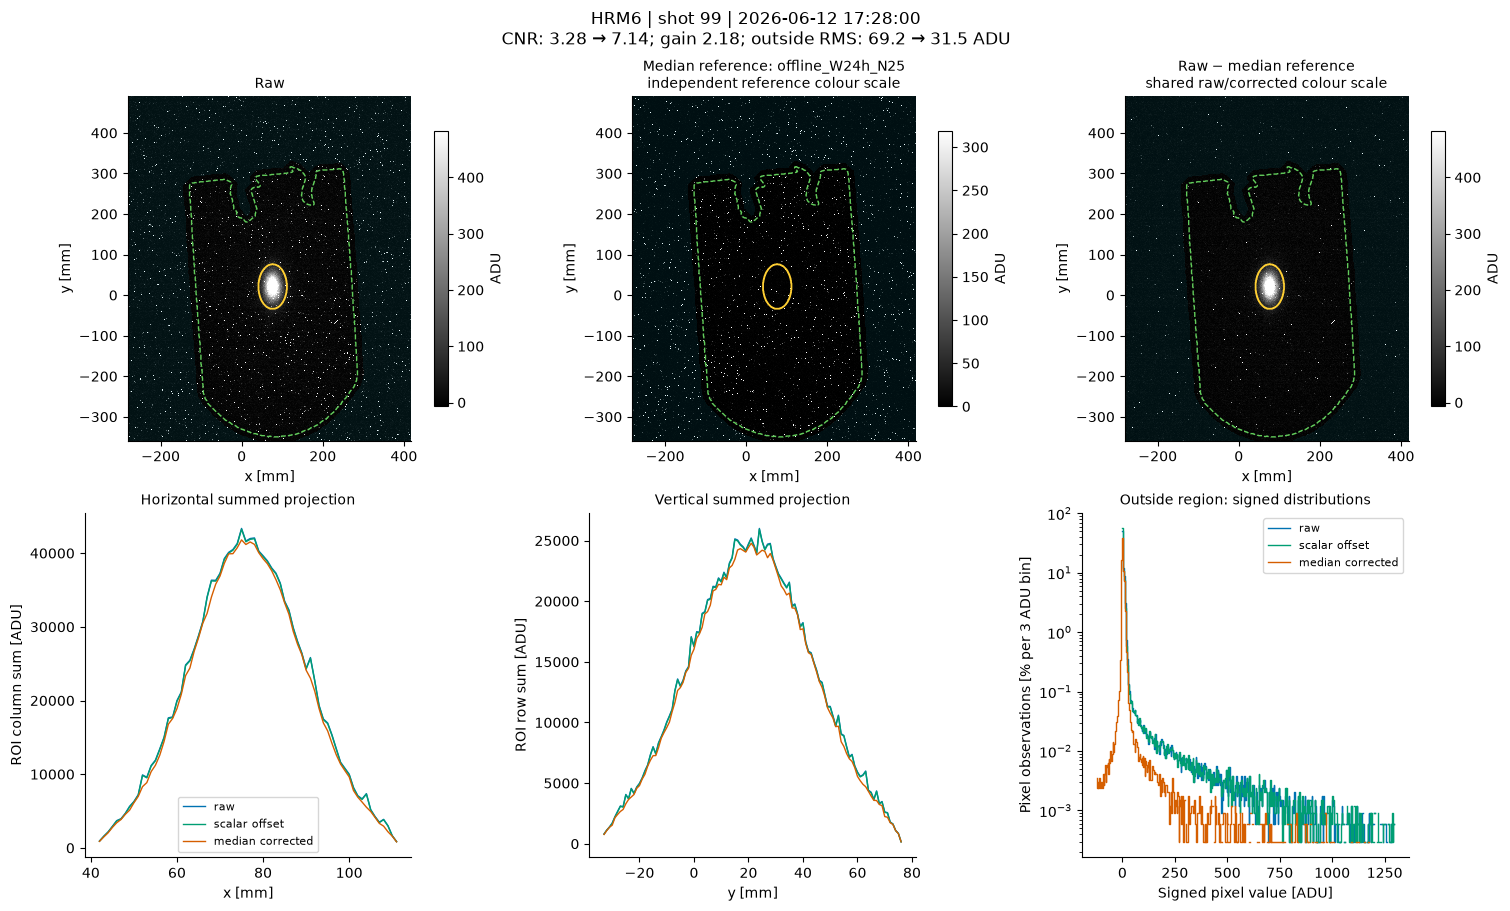

Shot 197, raw: histogram observations outside display = 0.0498%
Shot 197, scalar offset: histogram observations outside display = 0.0498%
Shot 197, median corrected: histogram observations outside display = 0.0747%


In [ ]:
examples = spread_sample(beams,min(int(N_EXAMPLE_SHOTS),len(beams))) if N_EXAMPLE_SHOTS else beams.iloc[:0]
if N_EXAMPLE_SHOTS and roi_mode=="ellipse_screen":
    representative_ids=roi_table.groupby("roi_kind",sort=False).head(1).row_id
    extra_examples=beams.loc[beams.row_id.isin(representative_ids) | beams.shot_number.eq(SCREEN_REFERENCE_SHOT)]
    examples=pd.concat([examples,extra_examples]).drop_duplicates("row_id").sort_values("shot_number")
ref = references[shown_id]
for shot in examples.itertuples():
    raw_cached=load_cached(shot.row_id)
    raw=raw_cached.astype(np.float64)
    corr=raw-ref
    b=roi_lookup[shot.row_id]
    roi,outside=region_masks(raw.shape,b)
    scalar=raw-float(np.median(raw_cached[outside]))
    lo=min(float(np.percentile(corr,1)),float(np.percentile(raw,1)),0)
    hi=max(float(np.percentile(raw,99.5)),float(np.percentile(corr,99.5)),lo+1)
    rlo,rhi=np.percentile(ref,[1,99.5]);rhi=max(rhi,rlo+1)
    fig,axes=plt.subplots(2,3,figsize=(15,9),constrained_layout=True)
    for ax,image,title,v0,v1 in [(axes[0,0],raw,"Raw",lo,hi),
        (axes[0,1],ref,f"Median reference: {shown_id}\nindependent reference colour scale",rlo,rhi),
        (axes[0,2],corr,"Raw − median reference\nshared raw/corrected colour scale",lo,hi)]:
        art=draw_image(ax,image,title,v0,v1,bounds=b)
        fig.colorbar(art,ax=ax,label="ADU",shrink=.8)
    for image,label,colour in [(raw,"raw",RAW_COLOUR),(scalar,"scalar offset",SCALAR_COLOUR),(corr,"median corrected",CORRECTED_COLOUR)]:
        axes[1,0].plot(plot_axes[0][b["x0"]:b["x1"]],np.where(roi,image,0.0).sum(axis=0)[b["x0"]:b["x1"]],label=label,color=colour,lw=1)
        axes[1,1].plot(plot_axes[1][b["y0"]:b["y1"]],np.where(roi,image,0.0).sum(axis=1)[b["y0"]:b["y1"]],label=label,color=colour,lw=1)
    axes[1,0].set(xlabel=f"x [{plot_units[0]}]",ylabel="ROI column sum [ADU]",title="Horizontal summed projection")
    axes[1,1].set(xlabel=f"y [{plot_units[1]}]",ylabel="ROI row sum [ADU]",title="Vertical summed projection")
    axes[1,0].legend()
    outs=[raw[outside],scalar[outside],corr[outside]]
    hist_low=np.floor(min(np.percentile(a,.05) for a in outs))-.5
    hist_high=np.ceil(max(np.percentile(a,99.95) for a in outs))+.5
    step=max(1,int(np.ceil((hist_high-hist_low)/600)))
    edges=np.arange(hist_low,hist_high+step,step)
    for a,label,colour in zip(outs,["raw","scalar offset","median corrected"],[RAW_COLOUR,SCALAR_COLOUR,CORRECTED_COLOUR]):
        counts,_=np.histogram(a,bins=edges)
        centres=(edges[:-1]+edges[1:])/2
        yy=100*counts/a.size
        axes[1,2].plot(centres,np.where(yy>0,yy,np.nan),drawstyle="steps-mid",label=label,color=colour,lw=1)
        omitted=100*np.mean((a<edges[0])|(a>edges[-1]))
        print(f"Shot {shot.shot_number}, {label}: histogram observations outside display = {omitted:.4f}%")
    axes[1,2].set(yscale="log",xlabel="Signed pixel value [ADU]",ylabel=f"Pixel observations [% per {step} ADU bin]",
                  title="Outside region: signed distributions")
    axes[1,2].legend()
    m=beam_metrics.loc[beam_metrics.row_id.eq(shot.row_id)].set_index("method")
    g=divide_positive_denominator(m.loc[shown_id,"cnr"],m.loc["raw","cnr"])
    fig.suptitle(f"{CAMERA_NAME.removesuffix('_g01')} | shot {shot.shot_number} | {shot.timestamp:%Y-%m-%d %H:%M:%S}\n"
                 f"CNR: {m.loc['raw','cnr']:.3g} → {m.loc[shown_id,'cnr']:.3g}; gain {g:.3g}; "
                 f"outside RMS: {m.loc['raw','outside_rms']:.3g} → {m.loc[shown_id,'outside_rms']:.3g} ADU")
    save_plot(fig,f"beam_example_{shot.shot_number:04d}_{shown_id}")

## 12. Save the complete numerical record

Every available candidate and paired shot is saved, including deterioration and undefined values. Blank CSV values
mean undefined (`NaN`), not zero. Reference membership preserves the exact source-row IDs and timestamps.
`selected_reference` records the no-beam RMSE choice; `shown_reference` can be overridden for inspection.
The raw cache is temporary and is not a corrected-image dataset. The median arrays and source membership allow
you to reproduce figures without rounding the reference.

`roi_bounds.csv` now includes ellipse kind, assignment source, actual centre/offset/radii, mask counts and screen
clipping fraction. `beam_metrics.csv` retains each shot's ROI kind/assignment. For ellipse mode, `screen_mask.npy`
and `offscreen_background_mask.npy` preserve the exact screen and guarded off-screen template. Together with
the saved per-shot geometry and guard settings they reproduce the beam masks. Screen-only pixels remain in
the corrected image arrays; they are excluded from **beam metric regions and masked projections**, not erased.
No-beam validation RMSE continues to use the whole image, including those coordinates.


In [ ]:
settings_record = dict(
    camera=CAMERA_NAME, parquet=str(PARQUET_PATH), filter=SELECTED_FILTER,
    analysis_start=str(T0), analysis_end=str(T1), timezone=LOCAL_TIMEZONE,
    configuration=configuration, missing_settings=missing_settings, dimension_order=DIMENSION_ORDER,
    background_counts=BACKGROUND_COUNTS, window_hours=BACKGROUND_WINDOW_HOURS, gap_hours=BACKGROUND_GAP_HOURS,
    reference_end_choices=REFERENCE_END_CHOICES,
    sampling="rounded linspace indices in chronological accepted pool; exact N; one deterministic subset",
    n_validation_requested=N_VALIDATION_BACKGROUNDS, n_validation_used=len(validation),
    validation_split="chronological earlier half for selection, later half for check; requires >=4 frames; offline mode reserves at most half of target backgrounds",
    selection_criterion="lowest selection median full-image signed residual RMSE; config_id breaks ties",
    selected_reference=chosen_id, shown_reference=shown_id,
    quality_rule=quality_rule, background_cuts="BTV: Q99-median>4; HRM3: mean>150 AND median>150; HRM6: none",
    roi_mode_requested=ROI_MODE, roi_mode=roi_mode,
    roi_size=ROI_SIZE_PIXELS if roi_mode=="square" else None,
    manual_center_xy=MANUAL_CENTER_XY, outside_margin=OUTSIDE_MARGIN_PIXELS,
    halo_semi_axes_pixels=HALO_SEMI_AXES_PIXELS, halo_angle_deg=HALO_ANGLE_DEG,
    halo_center_offset_xy_pixels=HALO_CENTER_OFFSET_XY_PIXELS,
    compact_semi_axes_pixels=COMPACT_SEMI_AXES_PIXELS, compact_angle_deg=COMPACT_ANGLE_DEG,
    compact_center_offset_xy_pixels=COMPACT_CENTER_OFFSET_XY_PIXELS,
    proton_only_shots=PROTON_ONLY_SHOTS, halo_shots=HALO_SHOTS,
    auto_propose_kind=AUTO_PROPOSE_KIND, broad_light_min_excess_adu=BROAD_LIGHT_MIN_EXCESS_ADU,
    shot_roi_overrides=SHOT_ROI_OVERRIDES,
    screen_reference_shot=SCREEN_REFERENCE_SHOT if roi_mode=="ellipse_screen" else None,
    screen_reference_row_id=screen_reference_id, screen_reference_timestamp=str(screen_reference_timestamp),
    screen_polygon_pixels=SCREEN_POLYGON_PIXELS, screen_outline_source=screen_source,
    screen_level_above_border_adu=SCREEN_LEVEL_ABOVE_BORDER_ADU,
    screen_guard_pixels=SCREEN_GUARD_PIXELS, signal_guard_pixels=SIGNAL_GUARD_PIXELS,
    signal_screen_intersection=roi_mode=="ellipse_screen",
    roi_extra_preview_shots=ROI_EXTRA_PREVIEW_SHOTS, show_all_roi_previews=SHOW_ALL_ROI_PREVIEWS,
    roi_mask_definition="ellipse intersect screen; background beyond guarded screen and guarded ellipse; remainder excluded" if roi_mode=="ellipse_screen" else "square and complement of guarded square",
    roi_geometry_version="hrm6_ellipse_screen_offset_v1",
    center_median_filter_size=CENTER_MEDIAN_FILTER_SIZE, center_smoothing=CENTER_SMOOTHING_SIZE,
    center_percentile=CENTER_TOP_PERCENTILE, max_beam_shots=MAX_BEAM_SHOTS,
    excess_delta_adu=EXCESS_DELTA_ADU, saturation_adu=SATURATION_ADU,
    sbr_min_background_adu=SBR_MIN_BACKGROUND_ADU,
    new_metrics_clip_negative=False, legacy_numerator_clips_positive=True,
    standard_deviation_ddof=0, mad_scale=1.4826, mad_fallback="std when MAD zero",
    axis_columns=[X_AXIS_COLUMN,Y_AXIS_COLUMN], axis_unit=AXIS_UNIT, axis_scale=AXIS_SCALE,
    check_axes_match=CHECK_AXES_MATCH, timestamp_column=TIMESTAMP_COLUMN, timestamp_unit=TIMESTAMP_UNIT,
    naive_timestamp_timezone=NAIVE_TIMESTAMP_TIMEZONE, beam_threshold=BEAM_THRESHOLD,
    bct_columns=BCT_COLUMNS, metadata_audit=metadata_audit,
    software=dict(numpy=np.__version__,pandas=pd.__version__,pyarrow=pa.__version__),
)
if SAVE_RESULTS:
    tables={"reference_grid":plan_table,"skipped_configurations":skipped_configs,
            "reference_membership":reference_membership,"validation_frames":validation,
            "validation_metrics":validation_metrics,"validation_summary":validation_summary,
            "selection_ranking":ranking,"beam_metrics":beam_metrics,
            "beam_ratio_summary":beam_ratio_summary,"beam_background_burden_summary":beam_burden_summary,
            "roi_bounds":roi_table,"image_rejections":rejections,"duplicate_timestamps":duplicate_rows,
            "accepted_image_inventory":valid_images}
    for name,frame in tables.items():
        frame.to_csv(RUN_DIR / f"{name}.csv",index=False)
    if roi_mode=="ellipse_screen":
        np.save(RUN_DIR/"screen_mask.npy",screen_mask,allow_pickle=False)
        np.save(RUN_DIR/"offscreen_background_mask.npy",offscreen_mask,allow_pickle=False)
    (RUN_DIR / "settings.json").write_text(json.dumps(settings_record,indent=2,default=str),encoding="utf-8")
    print("Saved all tables, settings and figures to:",RUN_DIR.resolve())
else:
    print("Saving disabled; results remain in notebook variables.")
print("No corrected-image parquet was created.")

## How to interpret the outcome in Chapter 5

**HRM6:** the hypothesis is that removal of recurrent bright structure reduces the outside spatial standard
deviation/tail and improves ROI CNR. Inspect the individual shots and validation RMSE. MAD may remain nearly
unchanged because it describes the central population rather than the rare tail. Conversely, transient tail features
that do not recur need not be removed by a median reference. The measured background behaviour alone does not
establish a radiation-damage mechanism.

**BTV:** a stable pedestal should become a small signed residual if matched. A lower RMS about zero and corrected
ROI sum can be meaningful even when CNR and spatial standard deviation do not change. Compare the pixel-wise
reference with scalar correction: if they perform similarly, state that this dataset mainly benefits from pedestal
removal. A large post-subtraction SBR caused by division by almost zero is not persuasive evidence.

**HRM3:** the same definitions may show small benefit for low backgrounds, stronger benefit later, or deterioration
from an unsuitable reference. Report that variation rather than selecting a different metric only for favourable cases.

For the selected reference, report the camera/filter/settings, reference membership and time coverage, independent
validation counts and RMSE, beam-shot count, paired median CNR gain with quartiles, improved/worse fractions,
outside RMS and tail changes, and numerator/negative/saturation checks. Use numerical results in sentences only
after running on the actual CERN parquet. This notebook contains no measured new HRM6 result before that run.

**What a successful result supports:** reduced recorded background/residual contamination and improved defined
image-separation measures under the selected conditions. It does not by itself prove exact beam-parameter accuracy,
absence of signal loss, or reduction of all temporal noise. ROIs/projections cannot replace per-shot ground truth.

Subtracting a fixed reference changes the level at a coordinate, not the temporal fluctuations already present in that
beam exposure. An uncertain independent reference can add uncertainty; a reduced **spatial** standard deviation
can still demonstrate removal of a recurrent pattern. Relevant background and noise distinctions are discussed by
[EMVA 1288, Release 4.0 Linear, Sections 2.5 and 4](https://www.emva.org/wp-content/uploads/EMVA1288Linear_4.0Release.pdf).
[STScI's background guidance](https://jwst-docs.stsci.edu/jwst-near-infrared-spectrograph/nirspec-observing-strategies/nirspec-background-recommended-strategies)
also notes that pixel-wise background subtraction can add noise; its astronomy application is different from HiRadMat.

**If the gain is small or negative:** inspect acquisition matching, reference age, early/late residuals, beam in the
outside region, saturation, negative tails and the ROI preview. A shorter analysis interval or more representative
reference may help. Changing the formula after inspecting which version looks best would turn the result into an
exploratory metric search; disclose such exploration and validate any final choice on separate data.

**Scope of the grid:** one deterministic subset per N/window, one fixed reference per interval, and no repeated-draw
uncertainty study. Use the full grid to identify plausible choices, then freeze a choice and repeat it on another day
for a stronger thesis result. The integrated/std proxy equals sqrt(ROI area) times CNR per shot. Its paired gains repeat CNR gains because that shot's mask is fixed; different halo/compact areas prevent treating its absolute values as one common rescaling across shots.
An offline candidate can use backgrounds acquired later than the beam shot or a validation image; its performance
must be described as retrospective, and should not be presented as a test of real-time reference availability.

When finished, the optional cell below deletes only the temporary raw-image cache. Run it only when you no longer
need to rerun the image-example cells. Saved CSVs, figures and median references remain available.

**ROI-specific interpretation:** keep halo and compact/run-log-confirmed cases identifiable using `roi_kind` and
`roi_assignment`. An image-based compact proposal is not proof of target absence. The 40-row halo shift and the
10/20 ADU geometry heuristics are starting values to review on raw images. Selecting offsets or shapes by their
CNR gain would bias the evaluation. A screen-clipped aperture may omit desired light if the screen outline is wrong.
Off-screen spatial statistics do not directly measure the unobserved background underneath the beam. The new
beam results use different regions from the old square study; full-image no-beam validation retains its definition.


In [ ]:
# Optional cleanup after finishing every inspection:
# cache_handle.cleanup()